# 2. Fase descriptiva: Análisis exploratorio de datos

Como un acercamiento inicial al análisis de los datos, se diseñó un esquema de exploración para examinar la estructura de las covariables e identificar empíricamente diferencias entre casos y controles, así como posibles patrones no lineales o dependencias espaciotemporales. Los apartados siguientes describen los análisis ejecutados sobre la muestra de entrenamiento.

## 1. Configuración y librerías

In [1]:
import sys
import subprocess

# Diccionario con el nombre del módulo al importar y el nombre del paquete en pip
librerias_requeridas = {
    'pandas': 'pandas',
    'matplotlib': 'matplotlib',
    'seaborn': 'seaborn',
    'numpy': 'numpy'
}

# Verificación e instalación dinámica
for modulo, paquete in librerias_requeridas.items():
    try:
        __import__(modulo)
    except ImportError:
        print(f"La librería '{modulo}' no se encontró. Iniciando instalación...")
        # Ejecuta el comando pip install usando el ejecutable actual de Python
        subprocess.check_call([sys.executable, "-m", "pip", "install", paquete])
        print(f"{modulo} se instaló exitosamente.")

# Imports estándar
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import seaborn as sns
import numpy as np

# Configuración del notebook
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', None)

print("Configuración inicial completada. Todo listo para trabajar.")

Configuración inicial completada. Todo listo para trabajar.


## 2. Lectura de datos

In [2]:
# Cargar conjunto de entrenamiento
df_train = pd.read_parquet("Generados/df_entrenamiento.parquet")
print("Conjunto de entrenamiento cargado")
display(df_train.head(5))
print(df_train.info())

Conjunto de entrenamiento cargado


,ID_RED,FECHA_FRANJA,TARGET,TIPO_MUESTRA,FESTIVO,FNSM,VACACIONES,PROMOCION,PANDEMIA,CARRILES,NIVEL,VELOCIDAD,LONGITUD,AVENIDA,BOULEVARD,CALLE,CAMINO,CARRETERA,CIRCUITO,GLORIETA,INCORPORACION,PRIVADA,RETORNO_U,MENOR,CERRADA_EN_AMBOS_SENTIDOS,DOS_SENTIDOS,UN_SENTIDO,GRADO_MIN,GRADO_MAX,DIST_NODO_3,DIST_NODO_4,DIST_NODO_5_MAS,SINUOSIDAD,DIST_MAN_PROH,DELTA_CARRILES_MAX,DELTA_CARRILES_MIN,DELTA_CARRILES_MEAN,DELTA_VELOCIDAD_MAX,DELTA_VELOCIDAD_MIN,DELTA_VELOCIDAD_MEAN,MES_SIN,MES_COS,DIASEMANA_SIN,DIASEMANA_COS,FRANJA_SIN,FRANJA_COS,PRECIP_SUM_PREV,PRECIP_MAX_PREV,WIND_GUSTS_MAX_PREV,WIND_SPEED_MEAN_PREV,TEMP_MEAN_PREV,TEMP_MIN_PREV,APP_TEMP_MEAN_PREV,CLOUD_COVER_MEAN_PREV,SOIL_TEMP_MEAN_PREV,SOIL_MOISTURE_MEAN_PREV,ACC_LOCAL_2W,ACC_LOCAL_1M,ACC_LOCAL_2M
0,877898_2,2019-02-28 06:00:00,1,accidente_real,0,0,0,0,0,2,1,50,141.243103,1,0,0,0,0,0,0,0,0,0,0,0,0,1,2,2,17.474588,18.400482,1261.830322,1.000215,771.981873,0,0,0.00,0,0,0.0,0.866025,0.5,0.433884,-0.900969,1.0,0.0,0.0,0.0,11.520000,6.623966,14.508334,13.500000,11.587700,60.666668,16.266666,0.088000,0,0,1
1,550482,2019-02-28 06:00:00,1,accidente_real,0,0,0,0,0,4,0,50,66.566269,1,0,0,0,0,0,0,0,0,0,0,0,0,1,3,3,33.468681,44.851730,830.587769,1.000029,215.829987,2,0,1.00,20,0,10.0,0.866025,0.5,0.433884,-0.900969,1.0,0.0,0.0,0.0,11.520000,6.623966,14.508334,13.500000,11.587700,60.666668,16.266666,0.088000,0,0,0
2,550075_1,2019-02-28 00:00:00,1,accidente_real,0,0,0,0,0,2,-1,50,135.857803,1,0,0,0,0,0,0,0,0,0,0,0,0,1,2,2,7.733476,34.290611,437.436035,1.000253,82.265244,0,0,0.00,0,0,0.0,0.866025,0.5,0.433884,-0.900969,0.0,1.0,0.0,0.0,24.480000,10.657967,20.616667,16.450001,16.645000,0.500000,25.308334,0.143167,0,0,0
3,4838974,2019-02-27 06:00:00,1,accidente_real,0,0,0,0,0,2,0,50,27.006979,0,1,0,0,0,0,0,0,0,0,0,0,0,1,3,3,13.579928,22.655237,948.448669,1.000000,41.158081,1,0,0.25,20,0,5.0,0.866025,0.5,0.974928,-0.222521,1.0,0.0,0.0,0.0,17.639999,7.038633,13.050000,10.800000,9.902467,0.000000,16.333334,0.139000,0,0,0
4,2639756,2019-02-28 00:00:00,1,accidente_real,0,0,0,0,0,4,0,50,127.648033,1,0,0,0,0,0,0,0,0,0,0,0,0,1,3,4,58.834480,64.181763,223.374161,1.000028,142.513748,3,0,0.80,20,0,8.0,0.866025,0.5,0.433884,-0.900969,0.0,1.0,0.0,0.0,25.200001,9.956166,21.533333,17.000000,17.786451,5.500000,25.000000,0.088000,0,0,0


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 76722 entries, 0 to 76721
Data columns (total 59 columns):
 #   Column                     Non-Null Count  Dtype         
---  ------                     --------------  -----         
 0   ID_RED                     76722 non-null  object        
 1   FECHA_FRANJA               76722 non-null  datetime64[ns]
 2   TARGET                     76722 non-null  int8          
 3   TIPO_MUESTRA               76722 non-null  object        
 4   FESTIVO                    76722 non-null  int8          
 5   FNSM                       76722 non-null  int8          
 6   VACACIONES                 76722 non-null  int8          
 7   PROMOCION                  76722 non-null  int8          
 8   PANDEMIA                   76722 non-null  int8          
 9   CARRILES                   76722 non-null  int8          
 10  NIVEL                      76722 non-null  int8          
 11  VELOCIDAD                  76722 non-null  int16         
 12  LONG

Se procede a separar el conjunto en casos y controles

In [3]:
# Accidentes
df_acc = df_train[df_train["TARGET"] == 1].copy()
print(f"Casos: {df_acc.shape[0]}")
display(df_acc.head(5))
df_acc_a = df_acc.copy()

# Controles
df_control = df_train[df_train["TARGET"] == 0].copy()
print(f"Controles: {df_control.shape[0]}")
display(df_control.head(5))

Casos: 15387


,ID_RED,FECHA_FRANJA,TARGET,TIPO_MUESTRA,FESTIVO,FNSM,VACACIONES,PROMOCION,PANDEMIA,CARRILES,NIVEL,VELOCIDAD,LONGITUD,AVENIDA,BOULEVARD,CALLE,CAMINO,CARRETERA,CIRCUITO,GLORIETA,INCORPORACION,PRIVADA,RETORNO_U,MENOR,CERRADA_EN_AMBOS_SENTIDOS,DOS_SENTIDOS,UN_SENTIDO,GRADO_MIN,GRADO_MAX,DIST_NODO_3,DIST_NODO_4,DIST_NODO_5_MAS,SINUOSIDAD,DIST_MAN_PROH,DELTA_CARRILES_MAX,DELTA_CARRILES_MIN,DELTA_CARRILES_MEAN,DELTA_VELOCIDAD_MAX,DELTA_VELOCIDAD_MIN,DELTA_VELOCIDAD_MEAN,MES_SIN,MES_COS,DIASEMANA_SIN,DIASEMANA_COS,FRANJA_SIN,FRANJA_COS,PRECIP_SUM_PREV,PRECIP_MAX_PREV,WIND_GUSTS_MAX_PREV,WIND_SPEED_MEAN_PREV,TEMP_MEAN_PREV,TEMP_MIN_PREV,APP_TEMP_MEAN_PREV,CLOUD_COVER_MEAN_PREV,SOIL_TEMP_MEAN_PREV,SOIL_MOISTURE_MEAN_PREV,ACC_LOCAL_2W,ACC_LOCAL_1M,ACC_LOCAL_2M
0,877898_2,2019-02-28 06:00:00,1,accidente_real,0,0,0,0,0,2,1,50,141.243103,1,0,0,0,0,0,0,0,0,0,0,0,0,1,2,2,17.474588,18.400482,1261.830322,1.000215,771.981873,0,0,0.00,0,0,0.0,0.866025,0.5,0.433884,-0.900969,1.0,0.0,0.0,0.0,11.520000,6.623966,14.508334,13.500000,11.587700,60.666668,16.266666,0.088000,0,0,1
1,550482,2019-02-28 06:00:00,1,accidente_real,0,0,0,0,0,4,0,50,66.566269,1,0,0,0,0,0,0,0,0,0,0,0,0,1,3,3,33.468681,44.851730,830.587769,1.000029,215.829987,2,0,1.00,20,0,10.0,0.866025,0.5,0.433884,-0.900969,1.0,0.0,0.0,0.0,11.520000,6.623966,14.508334,13.500000,11.587700,60.666668,16.266666,0.088000,0,0,0
2,550075_1,2019-02-28 00:00:00,1,accidente_real,0,0,0,0,0,2,-1,50,135.857803,1,0,0,0,0,0,0,0,0,0,0,0,0,1,2,2,7.733476,34.290611,437.436035,1.000253,82.265244,0,0,0.00,0,0,0.0,0.866025,0.5,0.433884,-0.900969,0.0,1.0,0.0,0.0,24.480000,10.657967,20.616667,16.450001,16.645000,0.500000,25.308334,0.143167,0,0,0
3,4838974,2019-02-27 06:00:00,1,accidente_real,0,0,0,0,0,2,0,50,27.006979,0,1,0,0,0,0,0,0,0,0,0,0,0,1,3,3,13.579928,22.655237,948.448669,1.000000,41.158081,1,0,0.25,20,0,5.0,0.866025,0.5,0.974928,-0.222521,1.0,0.0,0.0,0.0,17.639999,7.038633,13.050000,10.800000,9.902467,0.000000,16.333334,0.139000,0,0,0
4,2639756,2019-02-28 00:00:00,1,accidente_real,0,0,0,0,0,4,0,50,127.648033,1,0,0,0,0,0,0,0,0,0,0,0,0,1,3,4,58.834480,64.181763,223.374161,1.000028,142.513748,3,0,0.80,20,0,8.0,0.866025,0.5,0.433884,-0.900969,0.0,1.0,0.0,0.0,25.200001,9.956166,21.533333,17.000000,17.786451,5.500000,25.000000,0.088000,0,0,0


Controles: 61335


,ID_RED,FECHA_FRANJA,TARGET,TIPO_MUESTRA,FESTIVO,FNSM,VACACIONES,PROMOCION,PANDEMIA,CARRILES,NIVEL,VELOCIDAD,LONGITUD,AVENIDA,BOULEVARD,CALLE,CAMINO,CARRETERA,CIRCUITO,GLORIETA,INCORPORACION,PRIVADA,RETORNO_U,MENOR,CERRADA_EN_AMBOS_SENTIDOS,DOS_SENTIDOS,UN_SENTIDO,GRADO_MIN,GRADO_MAX,DIST_NODO_3,DIST_NODO_4,DIST_NODO_5_MAS,SINUOSIDAD,DIST_MAN_PROH,DELTA_CARRILES_MAX,DELTA_CARRILES_MIN,DELTA_CARRILES_MEAN,DELTA_VELOCIDAD_MAX,DELTA_VELOCIDAD_MIN,DELTA_VELOCIDAD_MEAN,MES_SIN,MES_COS,DIASEMANA_SIN,DIASEMANA_COS,FRANJA_SIN,FRANJA_COS,PRECIP_SUM_PREV,PRECIP_MAX_PREV,WIND_GUSTS_MAX_PREV,WIND_SPEED_MEAN_PREV,TEMP_MEAN_PREV,TEMP_MIN_PREV,APP_TEMP_MEAN_PREV,CLOUD_COVER_MEAN_PREV,SOIL_TEMP_MEAN_PREV,SOIL_MOISTURE_MEAN_PREV,ACC_LOCAL_2W,ACC_LOCAL_1M,ACC_LOCAL_2M
15387,549813_1,2019-02-26 06:00:00,0,ctrl_temp_1w,0,0,0,0,0,2,1,50,170.183212,1,0,0,0,0,0,0,0,0,0,0,0,0,1,2,2,41.973190,68.934448,601.533386,1.000011,51.532192,0,0,0.000000,0,0,0.000000,0.866025,0.5,0.781831,0.623490,1.0,0.0,0.0,0.0,10.080000,7.729733,12.333333,9.90,9.515017,7.5,15.083333,0.142000,0,0,0
15388,2610745,2019-02-26 18:00:00,0,ctrl_temp_1w,0,0,0,0,0,2,0,40,15.567952,1,0,0,0,0,0,0,0,0,0,0,0,1,0,3,4,7.827544,7.827544,383.662415,1.000000,591.437195,3,1,1.800000,10,10,10.000000,0.866025,0.5,0.781831,0.623490,-1.0,-0.0,0.0,0.0,33.840000,12.801483,26.441666,24.25,23.796083,1.0,29.383333,0.087333,1,0,0
15389,550550,2019-02-27 06:00:00,0,ctrl_temp_1w,0,0,0,0,0,3,0,50,19.303314,1,0,0,0,0,0,0,0,0,0,0,0,0,1,4,4,9.705794,9.705794,933.208984,1.000000,9.703918,0,0,0.000000,0,0,0.000000,0.866025,0.5,0.974928,-0.222521,1.0,0.0,0.0,0.0,17.280001,8.231917,14.008334,11.55,10.711534,0.0,16.141666,0.085000,1,0,0
15390,3241554,2019-02-27 12:00:00,0,ctrl_temp_1w,0,0,0,0,0,4,0,30,7.465720,0,0,1,0,0,0,0,0,0,0,0,0,1,0,4,4,3.753906,3.753906,419.822815,1.000000,0.000000,1,0,0.666667,10,0,6.666667,0.866025,0.5,0.974928,-0.222521,0.0,-1.0,0.0,0.0,18.360001,6.584784,15.275001,10.80,12.826251,0.0,15.441667,0.095833,0,0,0
15391,2546229,2019-02-27 12:00:00,0,ctrl_temp_1w,0,0,0,0,0,3,0,50,53.656746,1,0,0,0,0,0,0,0,0,0,0,0,0,1,3,3,26.979086,32.213745,334.288422,1.000000,306.268646,2,0,1.000000,20,0,5.000000,0.866025,0.5,0.974928,-0.222521,0.0,-1.0,0.0,0.0,18.360001,6.584784,15.275001,10.80,12.826251,0.0,15.441667,0.095833,0,0,0


Se definen etiquetas legibles para las variables y funciones auxiliares para construir tablas de frecuencia y preparar los datos de las gráficas.

In [4]:
# Diccionario con nombres de las variables
nombres_vars = {
    "DIST_NODO_5_MAS": "Dist. a nodo grado ≥5",
    "CAMINO": "Camino",
    "DIST_MAN_PROH": "Dist. a maniobra prohibida",
    "DIST_NODO_4": "Dist. a nodo grado 4",
    "WIND_SPEED_MEAN_PREV": "Velocidad viento previa",
    "SOIL_MOISTURE_MEAN_PREV": "Humedad suelo previa",
    "CLOUD_COVER_MEAN_PREV": "Cobertura nubes previa",
    "WIND_GUSTS_MAX_PREV": "Rachas viento previas",
    "SOIL_TEMP_MEAN_PREV": "Temp. suelo previa",
    "APP_TEMP_MEAN_PREV": "Temp. aparente previa",
    "TEMP_MEAN_PREV": "Temp. media previa",
    "TEMP_MIN_PREV": "Temp. mínima previa",
    "DIST_NODO_3": "Dist. a nodo grado 3",
    "LONGITUD": "Longitud",
    "SINUOSIDAD": "Sinuosidad",
    "VELOCIDAD": "Velocidad",
    "DELTA_VELOCIDAD_MEAN": "Cambio medio velocidad",
    "AVENIDA": "Avenida",
    "DELTA_CARRILES_MEAN": "Cambio medio carriles",
    "GRADO_MIN": "Grado mín. nodo",
    "GRADO_MAX": "Grado máx. nodo",
    "UN_SENTIDO": "Un sentido",
    "DIASEMANA_SIN": "Seno día semana",
    "MES_SIN": "Seno mes",
    "MES_COS": "Coseno mes",
    "CARRILES": "Número de carriles",
    "DELTA_VELOCIDAD_MAX": "Cambio máx. velocidad",
    "ACC_LOCAL_2M": "Accidentes 2 meses",
    "PRECIP_SUM_PREV": "Precip. acumulada previa",
    "PANDEMIA": "Pandemia",
    "PRECIP_MAX_PREV": "Precip. máx. previa",
    "DIASEMANA_COS": "Coseno día semana",
    "BOULEVARD": "Boulevard",
    "DELTA_CARRILES_MAX": "Cambio máx. carriles",
    "FRANJA_COS": "Coseno franja horaria",
    "CIRCUITO": "Circuito",
    "VACACIONES": "Vacaciones",
    "DOS_SENTIDOS": "Dos sentidos",
    "ACC_LOCAL_2W": "Accidentes 2 semanas",
    "FRANJA_SIN": "Seno franja horaria",
    "ACC_LOCAL_1M": "Accidentes 1 mes",
    "CARRETERA": "Carretera",
    "PRIVADA": "Privada",
    "CALLE": "Calle",
    "FESTIVO": "Festivo",
    "DELTA_VELOCIDAD_MIN": "Cambio mín. velocidad",
    "PROMOCION": "Promo. departamentales",
    "MENOR": "Vía menor",
    "NIVEL": "Nivel",
    "DELTA_CARRILES_MIN": "Cambio mín. carriles",
    "CERRADA_EN_AMBOS_SENTIDOS": "Cerrada ambos sentidos",
    "RETORNO_U": "Retorno en U",
    "INCORPORACION": "Incorporación",
    "FNSM": "Evento FNSM",
    "GLORIETA": "Glorieta",
    "TARGET":"Target"
}

In [5]:
# FUNCIONES
def tabla_crosstab_combinada(serie_target: pd.Series, serie_var: 
                             pd.Series,titulo: str, digits: int = 1) -> pd.DataFrame:
    """
    Genera una tabla de contingencia (crosstab) combinando conteos y porcentajes por fila,
    en formato 'N (pct%)'.

    Parámetros
    ----------
    `serie_target`: Serie categórica que se usará 
        como variable dependiente (filas).
    `serie_var`: Serie categórica que se usará 
        como variable independiente (columnas).
    `titulo`: Nombre para las columnas de la tabla resultante.
    `digits`: Número de decimales para los porcentajes
        (default=1).

    Retorna
    -------
    `df_display`: DataFrame con celdas en formato 'N (pct%)', incluyendo fila y columna 'Total'.
    """
    ct_counts = pd.crosstab(serie_target, serie_var, margins=True, margins_name='Total')
    ct_pct = ct_counts.div(ct_counts['Total'], axis=0) * 100
    
    df_display = pd.DataFrame(index=ct_counts.index, columns=ct_counts.columns)
    for row in ct_counts.index:
        for col in ct_counts.columns:
            conteo = ct_counts.loc[row, col]
            pct = ct_pct.loc[row, col]
            df_display.loc[row, col] = f"{int(conteo)} ({pct:.{digits}f}%)"
    
    df_display.index.name = 'Target'
    df_display.columns.name = titulo
    return df_display

def dummies_a_categoria(df: pd.DataFrame, columnas: list[str], nombres_vars: dict[str, str]) -> pd.Categorical:
    """
    Colapsa un conjunto de columnas dummy (one-hot encoding) en una sola serie categórica,
    conservando el orden original de la lista.

    Parámetros
    ----------
    `df`: DataFrame que contiene 
        las columnas dummy.
    `columnas`: Lista de nombres de 
        columnas dummy a colapsar.
    `nombres_vars`: Diccionario de mapeo 
        {columna_dummy: nombre_categórico}.

    Retorna
    -------
    `serie`: Serie categórica con las categorías en el orden especificado.
    """
    orden = [nombres_vars.get(c, c) for c in columnas]
    serie = df[columnas].idxmax(axis=1).map(lambda c: nombres_vars.get(c, c))
    return pd.Categorical(serie, categories=orden, ordered=True)

def frecuencia_y_texto(df_tabla: pd.DataFrame) -> tuple[pd.DataFrame, pd.DataFrame]:
    """
    Procesa una tabla con celdas 'N (pct%)' y devuelve dos DataFrames listos para graficar.

    Parámetros
    ----------
    `df_tabla`: Tabla con celdas en formato 'N (pct%)', 
        incluyendo fila y columna 'Total'.

    Retorna
    -------
    `df_plot`: DataFrame con conteos enteros para graficar.
    `df_texto`: DataFrame con texto formateado para anotaciones en gráficos.
    """
    base = df_tabla.drop(index="Total").drop(columns=["Total"]).T
    df_plot = base.map(lambda celda: int(celda.split(' ')[0]))
    df_texto = base.map(lambda celda: celda.replace(' ', '\n'))
    return df_plot, df_texto

## 3. Dinámica temporal: fecha y franja horaria

Se implementaron mapas de calor de frecuencia cruzada para examinar la variación intrasemanal (franja horaria de 6 horas frente a los 7 días de la semana) e interanual (los 12 meses del año frente a los años del periodo de entrenamiento). Este análisis se realiza solo sobre los registros de accidentes (`TARGET` = 1).

A partir de FECHA_FRANJA, se obtienen el día de la semana, la franja horaria, el mes y el año para ordenar las tablas y los mapas de calor.

In [6]:
# Traducciones
dias_map = {'Monday': 'Lunes', 'Tuesday': 'Martes', 'Wednesday': 'Miércoles', 'Thursday': 'Jueves', 
            'Friday': 'Viernes', 'Saturday': 'Sábado', 'Sunday': 'Domingo'
}

meses_map = {1: 'Enero', 2: 'Febrero', 3: 'Marzo', 4: 'Abril', 5: 'Mayo', 6: 'Junio', 7: 'Julio', 
             8: 'Agosto',9: 'Septiembre', 10: 'Octubre', 11: 'Noviembre', 12: 'Diciembre'
}

nombres_var = nombres_vars | {'DIA_SEMANA':'Día de la semana', 'FRANJA_HORARIA':'Franja Horaria', 'MES':'Mes', 'AÑO':'Año'}

# Orden de días y meses
dias_orden = ['Lunes', 'Martes', 'Miércoles', 'Jueves', 'Viernes', 'Sábado', 'Domingo']
meses_orden = ['Enero', 'Febrero', 'Marzo', 'Abril', 'Mayo', 'Junio',
               'Julio', 'Agosto', 'Septiembre', 'Octubre', 'Noviembre', 'Diciembre']

# Extraer componentes temporales
df_acc_a['DIA_SEMANA'] = df_acc['FECHA_FRANJA'].dt.day_name().map(dias_map)
df_acc_a['DIA_SEMANA'] = pd.Categorical(df_acc_a['DIA_SEMANA'], categories=dias_orden[::-1], ordered=True)

bins = [0, 6, 12, 18, 24]
labels = ['00:00-06:00', '06:00-12:00', '12:00-18:00', '18:00-24:00']
df_acc_a['FRANJA_HORARIA'] = pd.cut(df_acc_a['FECHA_FRANJA'].dt.hour, bins=bins, labels=labels, right=False)
df_acc_a['FRANJA_HORARIA'] = pd.Categorical(df_acc_a['FRANJA_HORARIA'], categories=labels, ordered=True)

df_acc_a['MES'] = df_acc['FECHA_FRANJA'].dt.month.map(meses_map)
df_acc_a['MES'] = pd.Categorical(df_acc_a['MES'], categories=meses_orden, ordered=True)
df_acc_a['AÑO'] = df_acc_a['FECHA_FRANJA'].dt.year
df_acc_a['AÑO'] = pd.Categorical(df_acc_a['AÑO'], categories=sorted(df_acc_a['FECHA_FRANJA'].dt.year.unique())[::-1], ordered=True)

Se calculan los conteos y la proporción relativa de accidentes para cada combinación de día y franja horaria, así como de año y mes.

Franja Horaria,00:00-06:00,06:00-12:00,12:00-18:00,18:00-24:00
Día de la semana,,,,
Domingo,0.421760,0.152506,0.165037,0.260697
Sábado,0.303893,0.155054,0.217206,0.323847
Viernes,0.204137,0.203237,0.255396,0.337230
Jueves,0.151240,0.227465,0.301270,0.320024
Miércoles,0.141345,0.262765,0.303238,0.292653
Martes,0.106218,0.253238,0.314767,0.325777
Lunes,0.256032,0.216642,0.260463,0.266864


Mes,Enero,Febrero,Marzo,Abril,Mayo,Junio,Julio,Agosto,Septiembre,Octubre,Noviembre,Diciembre
Año,,,,,,,,,,,,
2023,0.030875,0.085432,0.098022,0.034772,0.094424,0.100120,0.086631,0.085432,0.089928,0.093825,0.098621,0.101918
2022,0.073043,0.077246,0.078035,0.085391,0.090121,0.078035,0.081188,0.076984,0.086442,0.096427,0.079348,0.097740
2021,0.084334,0.072613,0.078045,0.083762,0.106346,0.082905,0.074042,0.070326,0.080332,0.091767,0.083762,0.091767
2020,0.083207,0.079803,0.088880,0.064297,0.069592,0.074130,0.082829,0.092663,0.085098,0.094175,0.078290,0.107035
2019,0.000000,0.007608,0.098906,0.097955,0.096529,0.098431,0.087019,0.098431,0.094151,0.095578,0.097480,0.127913


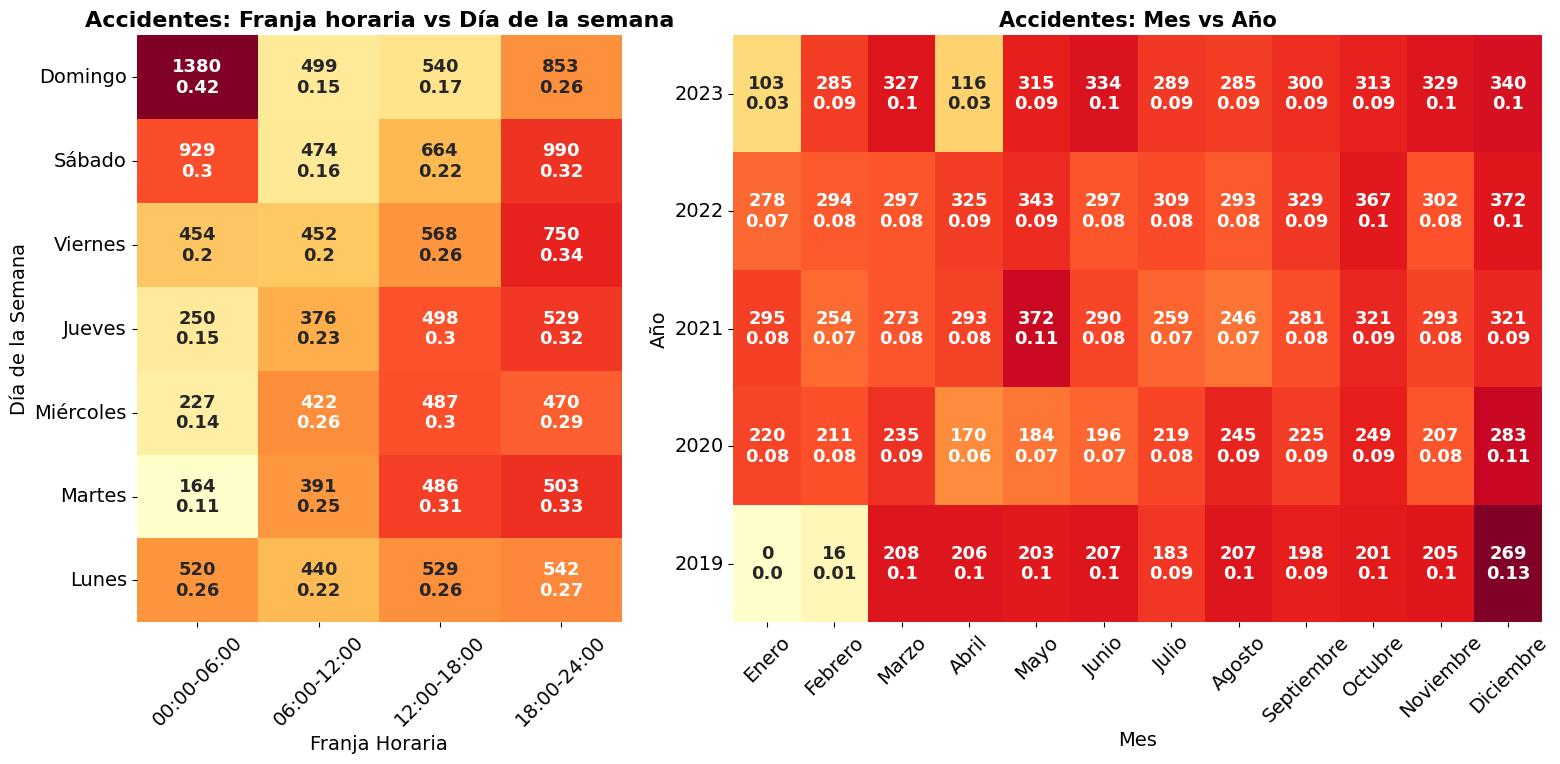

In [7]:
# Tablas cruzadas
ct_dias_franja_counts = pd.crosstab(df_acc_a['DIA_SEMANA'], df_acc_a['FRANJA_HORARIA'])
ct_dias_franja_norm = pd.crosstab(df_acc_a['DIA_SEMANA'], df_acc_a['FRANJA_HORARIA'], normalize='index')
# Renombres
ct_dias_franja_norm.index.name = nombres_var.get(ct_dias_franja_counts.index.name, ct_dias_franja_counts.index.name)
ct_dias_franja_norm.columns.name = nombres_var.get(ct_dias_franja_counts.columns.name, ct_dias_franja_counts.columns.name)
display(ct_dias_franja_norm)

# Crear anotaciones con conteo y proporción
annot_dias = ct_dias_franja_counts.astype(str) + "\n" + (ct_dias_franja_norm).round(2).astype(str)

# Tablas cruzadas
ct_año_mes_counts = pd.crosstab(df_acc_a['AÑO'], df_acc_a['MES'])
ct_año_mes_norm = pd.crosstab(df_acc_a['AÑO'], df_acc_a['MES'], normalize='index')
# Renombres
ct_año_mes_norm.index.name = nombres_var.get(ct_año_mes_counts.index.name, ct_año_mes_counts.index.name)
ct_año_mes_norm.columns.name = nombres_var.get(ct_año_mes_counts.columns.name, ct_año_mes_counts.columns.name)
display(ct_año_mes_norm)

# Crear anotaciones con conteo y proporción
annot_mes = ct_año_mes_counts.astype(str) + "\n" + (ct_año_mes_norm).round(2).astype(str)

# Figura
fig, axes = plt.subplots(1, 2, figsize=(16, 8), gridspec_kw={'width_ratios': [0.6, 1]})

sns.heatmap(ct_dias_franja_norm, cmap='YlOrRd', annot=annot_dias, fmt='', cbar=False, ax=axes[0], annot_kws={"size":13, "weight":'bold'})
axes[0].set_title('Accidentes: Franja horaria vs Día de la semana', fontsize=16, fontweight='bold')
axes[0].set_xlabel('Franja Horaria', fontsize=14)
axes[0].set_ylabel('Día de la Semana', fontsize=14)
axes[0].tick_params(axis='x', rotation=45, labelsize=14)
axes[0].tick_params(axis='y', rotation=0, labelsize=14)

sns.heatmap(ct_año_mes_norm, cmap='YlOrRd', annot=annot_mes, fmt='', cbar=False, ax=axes[1], annot_kws={"size":13, "weight":'bold'})
axes[1].set_title('Accidentes: Mes vs Año', fontsize=15, fontweight='bold')
axes[1].set_xlabel('Mes', fontsize=14)
axes[1].set_ylabel('Año', fontsize=14)
axes[1].tick_params(axis='x', rotation=45, labelsize=14)
axes[1].tick_params(axis='y', rotation=0, labelsize=14)

fig.tight_layout(pad=2.0)
plt.show()

Se consolidó un calendario diario para el periodo 2019–2024 mediante la identificación de días festivos, vacaciones escolares, la Feria Nacional de San Marcos (FNSM), periodos de promociones departamentales y pandemia. Estas categorías se codificaron mediante variables binarias independientes. La gráfica compara la proporción de accidentes ocurridos durante el estado activo e inactivo de cada condición.

,No activo,Activo
Evento,,
Festivo,94.027426,5.972574
Evento FNSM,96.542536,3.457464
Vacaciones,79.710145,20.289855
Promo. departamentales,93.949438,6.050562
Pandemia,71.982843,28.017157
Día sin evento (Normal),48.333008,51.666992


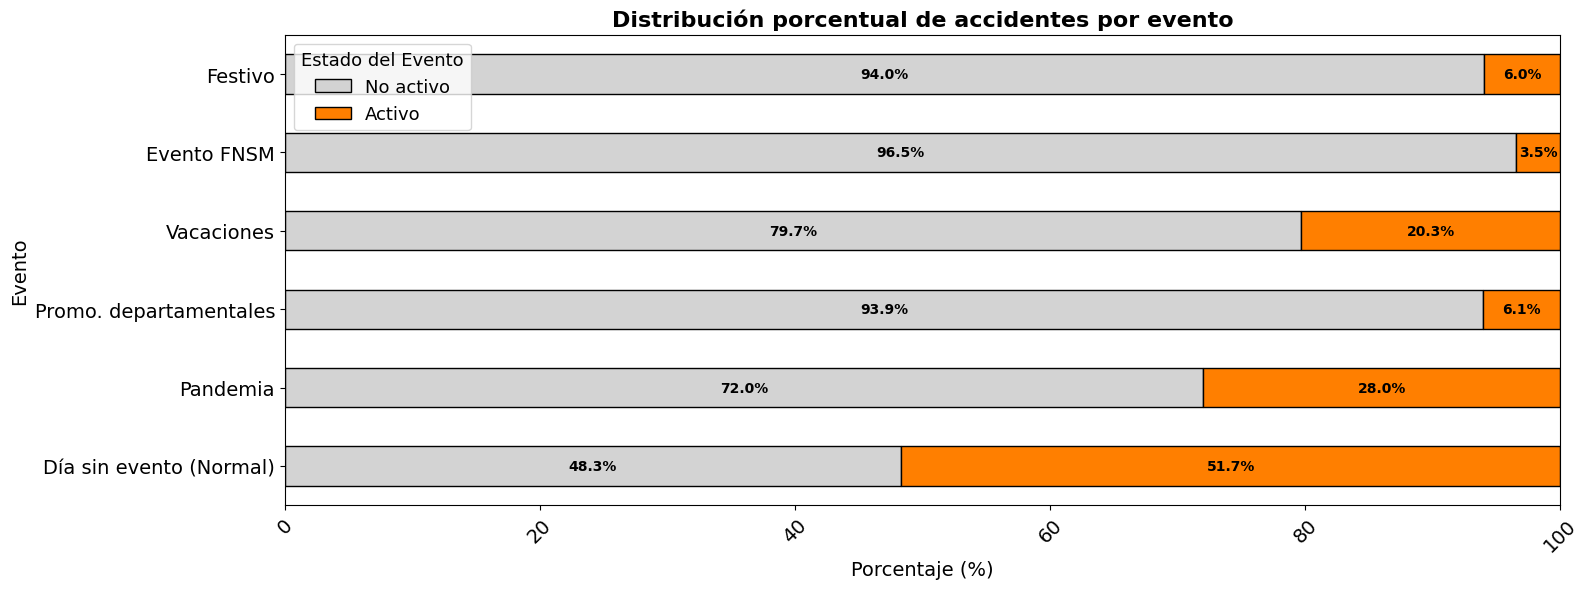

In [8]:
# Variables
var_contexto = ['FESTIVO', 'FNSM', 'VACACIONES', 'PROMOCION', 'PANDEMIA']

# Variable "SIN_EVENTO" (1 si todas son 0, 0 si hay algún evento)
df_acc_a['SIN_EVENTO'] = df_train[var_contexto].eq(0).all(axis=1).astype(int)
var_contexto.append('SIN_EVENTO')
nombres_vars['SIN_EVENTO'] = 'Día sin evento (Normal)'

# Calcular los porcentajes de 0 y 1 para cada variable en df_acc_a
datos_apilados = []

for var in var_contexto:
    # Contamos cuántos 0s y 1s hay en esa columna
    conteos = df_acc_a[var].value_counts()
    cero = conteos.get(0, 0)
    uno = conteos.get(1, 0)
    total = cero + uno
    
    # Porcentaje
    pct_cero = (cero / total) * 100
    pct_uno = (uno / total) * 100
    
    # Guardamos con el nombre
    nombre = nombres_vars.get(var, var)
    datos_apilados.append({
        'Evento': nombre,
        'No activo': pct_cero,
        'Activo': pct_uno
    })

# DataFrame con los porcentajes calculados
df_plot = pd.DataFrame(datos_apilados).set_index('Evento')
display(df_plot)

# Grafico de barras apiladas al 100% de forma horizontal
ax = df_plot[::-1].plot(kind='barh', stacked=True, figsize=(16, 6), color=['#d3d3d3', '#FF7F00'], edgecolor='black')

plt.title('Distribución porcentual de accidentes por evento', fontsize=16, fontweight='bold')
plt.xlabel('Porcentaje (%)', fontsize=14)
plt.ylabel('Evento', fontsize=14)
plt.tick_params(axis='x', rotation=45, labelsize=14)
plt.tick_params(axis='y', rotation=0, labelsize=14)
plt.xlim(0, 100)

# Etiquetas
for p in ax.patches:
    width = p.get_width()
    x_pos = p.get_x() + width / 2
    y_pos = p.get_y() + p.get_height() / 2
    
    ax.text(x_pos, y_pos, f'{width:.1f}%', 
            ha='center', va='center', fontsize=10, color='black', fontweight='bold')

# Mover la leyenda afuera para que no tape las barras
plt.legend(loc='upper left', title='Estado del Evento', fontsize=13, title_fontsize=13)
plt.tight_layout()
plt.show()

## 4. Caracterización de la infraestructura vial

Para inspeccionar las características geométricas y de diseño de la Red Nacional de Caminos (RNC), las covariables viales se clasificaron según su tipo de dato y se compararon entre `Control` y `Accidente`.

### 4.1 Variables categóricas nominales
Se generaron tablas de frecuencia y gráficos de barras comparativos para el tipo de vialidad y el sentido de circulación, desglosados por clase.


TABLA: Tipo de vialidad


Tipo de vialidad,Avenida,Boulevard,Calle,Camino,Carretera,Circuito,Glorieta,Incorporación,Privada,Retorno en U,Vía menor,Total
Target,,,,,,,,,,,,
Control (0),18946 (30.9%),3069 (5.0%),18088 (29.5%),7332 (12.0%),7763 (12.7%),547 (0.9%),514 (0.8%),688 (1.1%),1127 (1.8%),1424 (2.3%),1837 (3.0%),61335 (100.0%)
Accidente (1),7402 (48.1%),1261 (8.2%),4163 (27.1%),93 (0.6%),1362 (8.9%),30 (0.2%),95 (0.6%),95 (0.6%),44 (0.3%),476 (3.1%),366 (2.4%),15387 (100.0%)
Total,26348 (34.3%),4330 (5.6%),22251 (29.0%),7425 (9.7%),9125 (11.9%),577 (0.8%),609 (0.8%),783 (1.0%),1171 (1.5%),1900 (2.5%),2203 (2.9%),76722 (100.0%)



TABLA: Sentido vial


Sentido vial,Un sentido,Dos sentidos,Cerrada ambos sentidos,Total
Target,,,,
Control (0),35491 (57.9%),25159 (41.0%),685 (1.1%),61335 (100.0%)
Accidente (1),11875 (77.2%),3484 (22.6%),28 (0.2%),15387 (100.0%)
Total,47366 (61.7%),28643 (37.3%),713 (0.9%),76722 (100.0%)


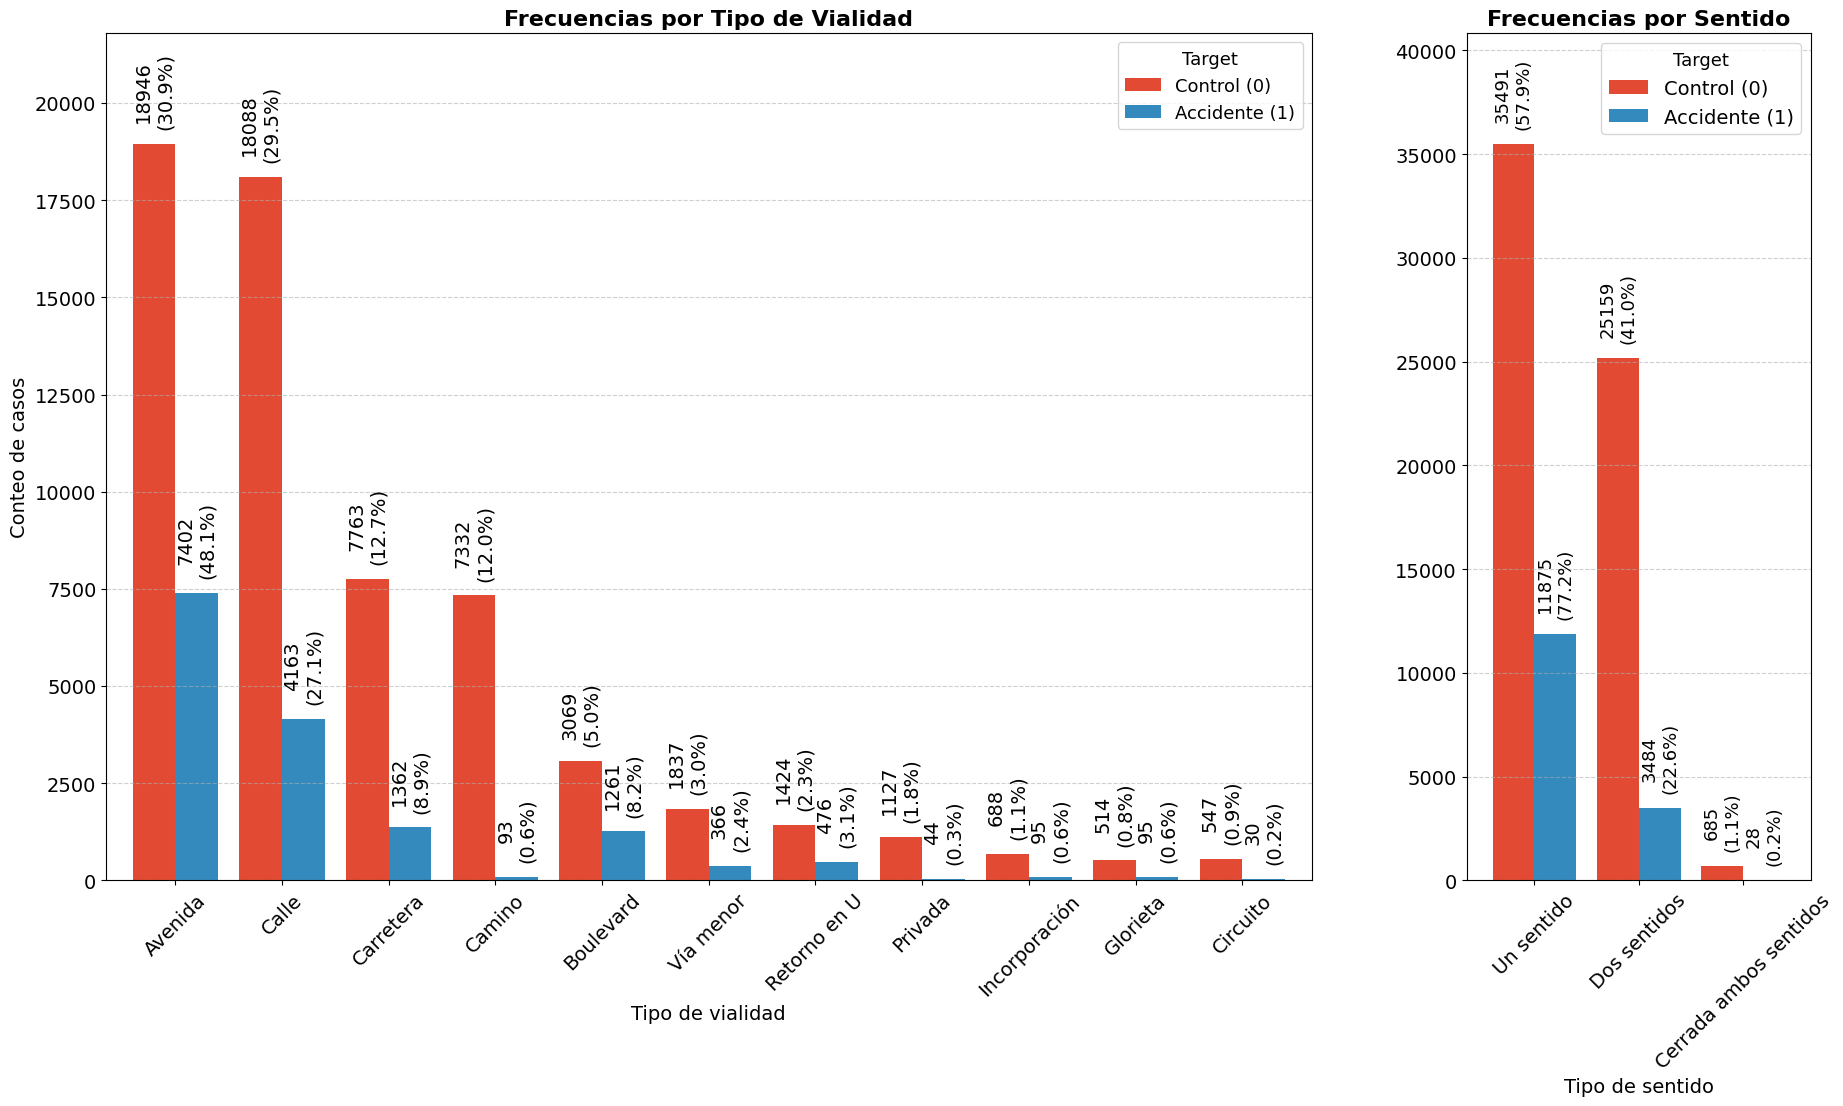

In [9]:
# Grupos
tipo_vialidad = ['AVENIDA', 'BOULEVARD', 'CALLE', 'CAMINO', 'CARRETERA', 'CIRCUITO', 
                 'GLORIETA', 'INCORPORACION', 'PRIVADA', 'RETORNO_U', 'MENOR']

sentido_vialidad = ['UN_SENTIDO', 'DOS_SENTIDOS', 'CERRADA_EN_AMBOS_SENTIDOS']

# Target como categórica ordenada
serie_target = pd.Categorical(
    df_train['TARGET'].map({0: 'Control (0)', 1: 'Accidente (1)'}),
    categories=['Control (0)', 'Accidente (1)'], ordered=True
)

serie_tipo = dummies_a_categoria(df_train, tipo_vialidad, nombres_vars)
df_tipo = tabla_crosstab_combinada(serie_target, serie_tipo, "Tipo de vialidad")
print("\nTABLA: Tipo de vialidad")
display(df_tipo)

serie_sentido = dummies_a_categoria(df_train, sentido_vialidad, nombres_vars)
df_sentido = tabla_crosstab_combinada(serie_target, serie_sentido, "Sentido vial")
print("\nTABLA: Sentido vial")
display(df_sentido)

# Frecuencia y texto para el gráfico, extraídos de las tablas combinadas
df_plot_tipo, df_texto_tipo = frecuencia_y_texto(df_tipo)
df_plot_sentido, df_texto_sentido = frecuencia_y_texto(df_sentido)

# Orden de mayor a menor
df_plot_tipo['Suma'] = df_plot_tipo.sum(axis=1)
df_plot_tipo = df_plot_tipo.sort_values('Suma', ascending=False).drop(columns=['Suma'])
df_texto_tipo = df_texto_tipo.reindex(df_plot_tipo.index)

df_plot_sentido['Suma'] = df_plot_sentido.sum(axis=1)
df_plot_sentido = df_plot_sentido.sort_values('Suma', ascending=False).drop(columns=['Suma'])
df_texto_sentido = df_texto_sentido.reindex(df_plot_sentido.index)

# Gráfico
fig, axes = plt.subplots(1, 2, figsize=(22, 11), gridspec_kw={'width_ratios': [2.1, 0.6]})
colores = ['#E24A33', '#348ABD']

# Tipo de Vialidad
df_plot_tipo.plot(kind='bar', ax=axes[0], color=colores, width=0.8)
axes[0].set_title('Frecuencias por Tipo de Vialidad', fontsize=16, fontweight='bold')
axes[0].set_xlabel('Tipo de vialidad', fontsize=14)
axes[0].set_ylabel('Conteo de casos', fontsize=14)
axes[0].tick_params(axis='x', rotation=45, labelsize=14)
axes[0].tick_params(axis='y', rotation=0, labelsize=14)
axes[0].grid(axis='y', linestyle='--', alpha=0.6)

max_val_tipo = df_plot_tipo.max().max()
axes[0].set_ylim(0, max_val_tipo * 1.15)

conteos_tipo = df_plot_tipo.values.flatten('F')
textos_tipo = df_texto_tipo.values.flatten('F')

for p, conteo, texto in zip(axes[0].patches, conteos_tipo, textos_tipo):
    if conteo > 0:
        axes[0].text(p.get_x() + p.get_width() / 2., p.get_height() + (max_val_tipo * 0.02),
                     texto, ha='center', va='bottom', fontsize=14, color='black', rotation=90)

axes[0].legend(['Control (0)', 'Accidente (1)'], title='Target', fontsize=13, title_fontsize=13)

# Sentido Vial
df_plot_sentido.plot(kind='bar', ax=axes[1], color=colores, width=0.8)
axes[1].set_title('Frecuencias por Sentido', fontsize=16, fontweight='bold')
axes[1].set_xlabel('Tipo de sentido', fontsize=14)
axes[1].set_ylabel('', fontsize=14)
axes[1].tick_params(axis='x', rotation=45, labelsize=14)
axes[1].tick_params(axis='y', rotation=0, labelsize=14)
axes[1].grid(axis='y', linestyle='--', alpha=0.6)

max_val_sentido = df_plot_sentido.max().max()
axes[1].set_ylim(0, max_val_sentido * 1.15)

conteos_sentido = df_plot_sentido.values.flatten('F')
textos_sentido = df_texto_sentido.values.flatten('F')

for p, conteo, texto in zip(axes[1].patches, conteos_sentido, textos_sentido):
    if conteo > 0:
        axes[1].text(p.get_x() + p.get_width() / 2., p.get_height() + (max_val_sentido * 0.02),
                     texto, ha='center', va='bottom', fontsize=13, color='black', rotation=90)

axes[1].legend(['Control (0)', 'Accidente (1)'], title='Target', fontsize=14, title_fontsize=13)
plt.show()

### 4.2 Variables categóricas ordinales
Se contrastan las distribuciones de casos frente a controles mediante paneles de barras para `NIVEL`, `GRADO_MIN`, `GRADO_MAX`, `VELOCIDAD`, `CARRILES` y los deltas extremos de carriles y velocidad (`DELTA_CARRILES_MAX`, `DELTA_CARRILES_MIN`, `DELTA_VELOCIDAD_MAX` y `DELTA_VELOCIDAD_MIN`).


TABLA: Número de carriles


Número de carriles,1,2,3,4,5,6,Total
Target,,,,,,,
Control (0),8736 (14.2%),30859 (50.3%),18183 (29.6%),3282 (5.4%),170 (0.3%),105 (0.2%),61335 (100.0%)
Accidente (1),1072 (7.0%),7261 (47.2%),5881 (38.2%),1066 (6.9%),68 (0.4%),39 (0.3%),15387 (100.0%)
Total,9808 (12.8%),38120 (49.7%),24064 (31.4%),4348 (5.7%),238 (0.3%),144 (0.2%),76722 (100.0%)



TABLA: Cambio máx. carriles


Cambio máx. carriles,0,1,2,3,4,5,Total
Target,,,,,,,
Control (0),25657 (41.8%),24289 (39.6%),9022 (14.7%),2037 (3.3%),302 (0.5%),28 (0.0%),61335 (100.0%)
Accidente (1),4972 (32.3%),6746 (43.8%),2858 (18.6%),704 (4.6%),100 (0.6%),7 (0.0%),15387 (100.0%)
Total,30629 (39.9%),31035 (40.5%),11880 (15.5%),2741 (3.6%),402 (0.5%),35 (0.0%),76722 (100.0%)



TABLA: Cambio mín. carriles


...


TABLA: Cambio máx. velocidad


Cambio máx. velocidad,0,5,10,20,25,30,35,40,45,50,55,60,70,80,Total
Target,,,,,,,,,,,,,,,
Control (0),27191 (44.33%),180 (0.29%),5702 (9.30%),15081 (24.59%),1165 (1.90%),6486 (10.57%),56 (0.09%),3732 (6.08%),220 (0.36%),952 (1.55%),6 (0.01%),338 (0.55%),200 (0.33%),26 (0.04%),61335 (100.00%)
Accidente (1),5628 (36.58%),1 (0.01%),1881 (12.22%),4453 (28.94%),200 (1.30%),1848 (12.01%),6 (0.04%),1056 (6.86%),48 (0.31%),173 (1.12%),0 (0.00%),64 (0.42%),26 (0.17%),3 (0.02%),15387 (100.00%)
Total,32819 (42.78%),181 (0.24%),7583 (9.88%),19534 (25.46%),1365 (1.78%),8334 (10.86%),62 (0.08%),4788 (6.24%),268 (0.35%),1125 (1.47%),6 (0.01%),402 (0.52%),226 (0.29%),29 (0.04%),76722 (100.00%)



TABLA: Cambio mín. velocidad


Cambio mín. velocidad,0,5,10,15,20,25,30,35,40,45,50,60,70,Total
Target,,,,,,,,,,,,,,
Control (0),58124 (94.76%),92 (0.15%),729 (1.19%),1 (0.00%),1257 (2.05%),108 (0.18%),491 (0.80%),5 (0.01%),420 (0.68%),5 (0.01%),62 (0.10%),27 (0.04%),14 (0.02%),61335 (100.00%)
Accidente (1),14678 (95.39%),3 (0.02%),231 (1.50%),0 (0.00%),246 (1.60%),4 (0.03%),94 (0.61%),0 (0.00%),115 (0.75%),0 (0.00%),7 (0.05%),7 (0.05%),2 (0.01%),15387 (100.00%)
Total,72802 (94.89%),95 (0.12%),960 (1.25%),1 (0.00%),1503 (1.96%),112 (0.15%),585 (0.76%),5 (0.01%),535 (0.70%),5 (0.01%),69 (0.09%),34 (0.04%),16 (0.02%),76722 (100.00%)


C:\Users\bryan\AppData\Local\Temp\ipykernel_33076\3867556900.py:87: MatplotlibDeprecationWarning: You have mixed positional and keyword arguments, some input may be discarded.  This is deprecated since 3.9 and will become an error in 3.11.
  fig1.legend(handles, labels=['Control (0)', 'Accidente (1)'], loc='upper center',


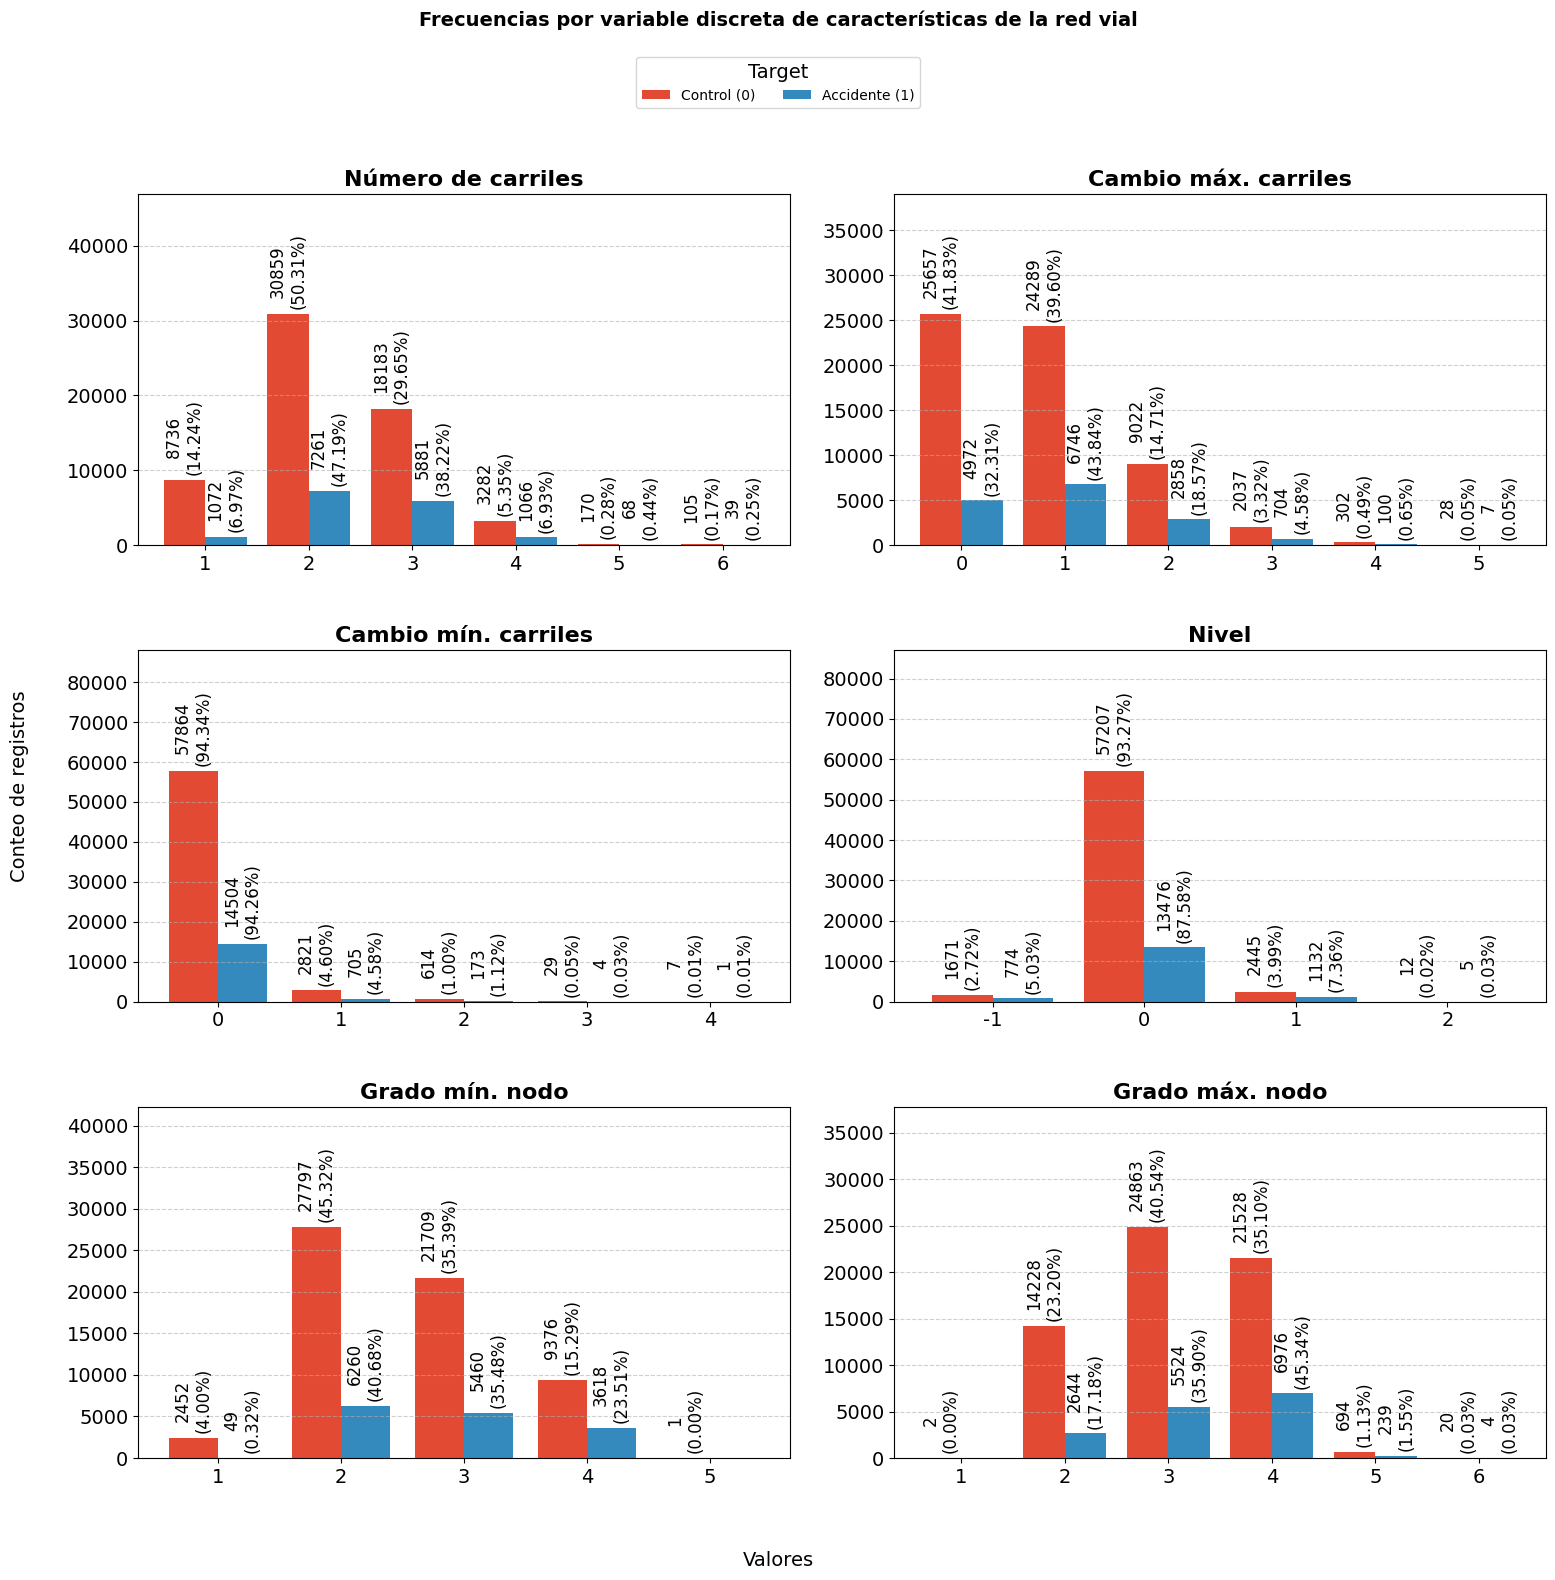

C:\Users\bryan\AppData\Local\Temp\ipykernel_33076\3867556900.py:137: MatplotlibDeprecationWarning: You have mixed positional and keyword arguments, some input may be discarded.  This is deprecated since 3.9 and will become an error in 3.11.
  fig2.legend(handles, labels=['Control (0)', 'Accidente (1)'], loc='upper center',


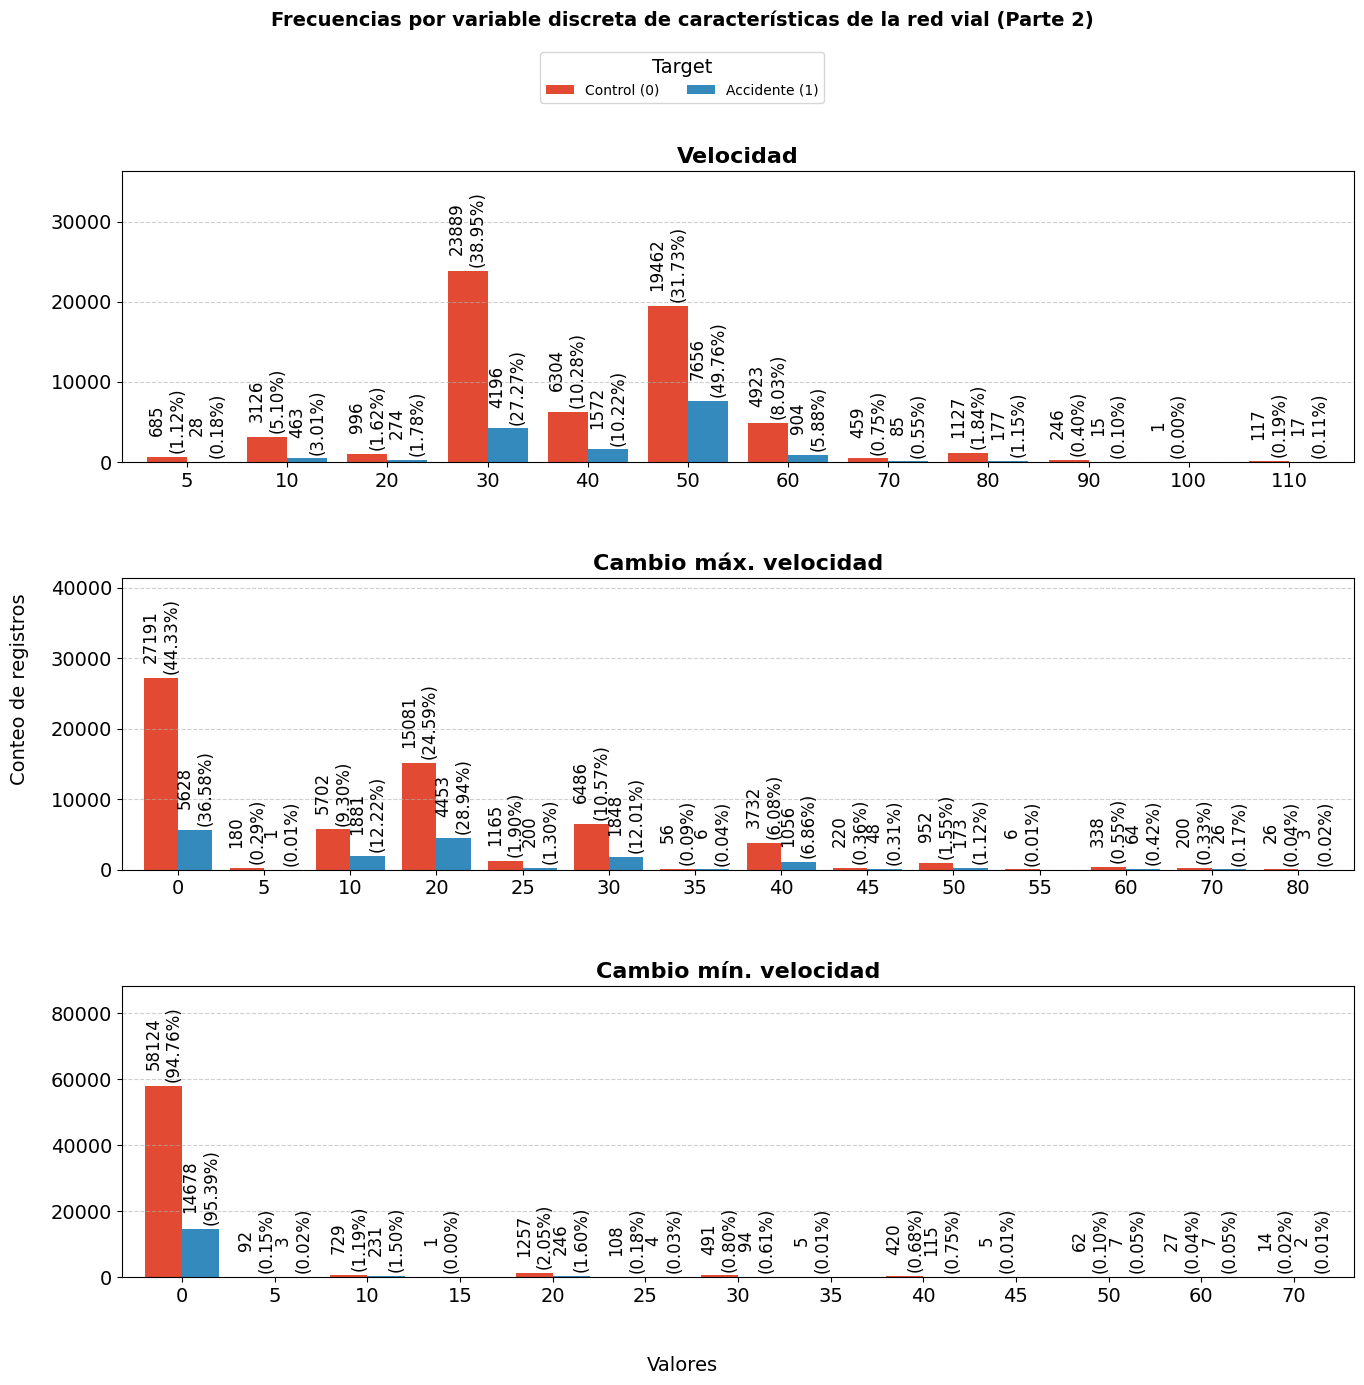

In [10]:
# Variables
var_vial_discretas = [
    'CARRILES', 'DELTA_CARRILES_MAX', 'DELTA_CARRILES_MIN', 
    'NIVEL', 'GRADO_MIN', 'GRADO_MAX', 
    'VELOCIDAD', 'DELTA_VELOCIDAD_MAX', 'DELTA_VELOCIDAD_MIN'
]

# Target como categórica ordenada
serie_target = pd.Categorical(
    df_train['TARGET'].map({0: 'Control (0)', 1: 'Accidente (1)'}),
    categories=['Control (0)', 'Accidente (1)'], ordered=True
)

for var in var_vial_discretas:
    titulo = nombres_vars.get(var, var)
    df_display = tabla_crosstab_combinada(serie_target, df_train[var], titulo)
    print(f"\nTABLA: {titulo}")
    display(df_display)

colores = ['#E24A33', '#348ABD']

# TABLAS DE FRECUENCIAS Y EXTRACCIÓN DE DATOS PARA PLOT
# Diccionarios para almacenar los datos de los gráficos de cada variable
dict_plot = {}
dict_texto = {}

for var in var_vial_discretas:
    titulo = nombres_vars.get(var, var)
    
    # Tabla
    df_display = tabla_crosstab_combinada(serie_target, df_train[var], titulo, digits=2)
    
    print(f"\nTABLA: {titulo}")
    display(df_display)
    
    # Extraer las frecuencias y los textos
    df_plot, df_texto = frecuencia_y_texto(df_display)
    
    # No se ordena, para conservar el orden lógico de las variables discretas
    dict_plot[var] = df_plot
    dict_texto[var] = df_texto

# SEPARACIÓN DE VARIABLES
vars_bloque_1 = var_vial_discretas[:6] # Primeras 6 variables (Grid 3x2)
vars_bloque_2 = var_vial_discretas[6:] # Últimas 3 variables (Grid 3x1)

# GRÁFICO 1: Cuadrícula 3x2 (6 subplots)
fig1, axes1 = plt.subplots(3, 2, figsize=(16, 16))
axes_bar1 = axes1.flatten()

for i, var in enumerate(vars_bloque_1):
    ax = axes_bar1[i]
    titulo = nombres_vars.get(var, var)
    
    df_plot_actual = dict_plot[var]
    df_texto_actual = dict_texto[var]
    
    df_plot_actual.plot(kind='bar', ax=ax, color=colores, width=0.8)
    
    ax.set_title(f'{titulo}', fontsize=16, fontweight='bold')
    ax.set_xlabel('')
    ax.set_ylabel('')
    ax.tick_params(axis='x', rotation=0, labelsize=14)
    ax.tick_params(axis='y', rotation=0, labelsize=14)
    ax.grid(axis='y', linestyle='--', alpha=0.6)
    
    max_val = df_plot_actual.max().max()
    ax.set_ylim(0, max_val * 1.52)
    
    conteos = df_plot_actual.values.flatten('F')
    textos = df_texto_actual.values.flatten('F')
    
    for p, conteo, texto in zip(ax.patches, conteos, textos):
        if conteo > 0:
            ax.text(
                p.get_x() + p.get_width() / 2., 
                p.get_height() + (max_val * 0.02),
                texto, 
                ha='center', va='bottom', fontsize=12, color='black', rotation=90
            )

    if ax.get_legend() is not None:
        ax.get_legend().remove()

# Leyenda y títulos globales para la Figura 1
handles, labels = axes_bar1[0].get_legend_handles_labels()
fig1.legend(handles, labels=['Control (0)', 'Accidente (1)'], loc='upper center', 
            bbox_to_anchor=(0.5, 0.96), ncol=2, frameon=True, title='Target', 
            fontsize=10, title_fontsize=14)

fig1.suptitle("Frecuencias por variable discreta de características de la red vial", fontsize=14, fontweight='bold', y=0.985)
fig1.supylabel('Conteo de registros', fontsize=14)
fig1.supxlabel('Valores', fontsize=14)

fig1.subplots_adjust(top=0.87, bottom=0.08, left=0.1, right=0.98, hspace=0.3, wspace=0.16)
plt.show(fig1)

# GRÁFICO 2: Cuadrícula 3x1
fig2, axes2 = plt.subplots(3, 1, figsize=(14, 14))
axes_bar2 = axes2.flatten()

for i, var in enumerate(vars_bloque_2):
    ax = axes_bar2[i]
    titulo = nombres_vars.get(var, var)
    
    df_plot_actual = dict_plot[var]
    df_texto_actual = dict_texto[var]
    
    df_plot_actual.plot(kind='bar', ax=ax, color=colores, width=0.8)
    
    ax.set_title(f'{titulo}', fontsize=16, fontweight='bold')
    ax.set_xlabel('')
    ax.set_ylabel('')
    ax.tick_params(axis='x', rotation=0, labelsize=14)
    ax.tick_params(axis='y', rotation=0, labelsize=14)
    ax.grid(axis='y', linestyle='--', alpha=0.6)
    
    max_val = df_plot_actual.max().max()
    ax.set_ylim(0, max_val * 1.52)
    
    conteos = df_plot_actual.values.flatten('F')
    textos = df_texto_actual.values.flatten('F')
    
    for p, conteo, texto in zip(ax.patches, conteos, textos):
        if conteo > 0:
            ax.text(
                p.get_x() + p.get_width() / 2., 
                p.get_height() + (max_val * 0.02),
                texto, 
                ha='center', va='bottom', fontsize=12, color='black', rotation=90
            )

    if ax.get_legend() is not None:
        ax.get_legend().remove()

# Leyenda y títulos globales para la Figura 2
fig2.legend(handles, labels=['Control (0)', 'Accidente (1)'], loc='upper center', 
            bbox_to_anchor=(0.5, 0.96), ncol=2, frameon=True, title='Target', 
            fontsize=10, title_fontsize=14)

fig2.suptitle("Frecuencias por variable discreta de características de la red vial (Parte 2)", fontsize=14, fontweight='bold', y=0.985)
fig2.supylabel('Conteo de registros', fontsize=14)
fig2.supxlabel('Valores', fontsize=14)

fig2.subplots_adjust(top=0.87, bottom=0.08, left=0.1, right=0.98, hspace=0.4)
plt.show(fig2)

### 4.3 Variables continuas

Se comparan mediante diagramas de violín las distribuciones de `DIST_NODO_3`, `DIST_NODO_4`, `DIST_NODO_5_MAS`, `DIST_MAN_PROH`, `LONGITUD`, `SINUOSIDAD`, `DELTA_CARRILES_MEAN` y `DELTA_VELOCIDAD_MEAN`. Para reducir el efecto visual de las colas largas, la gráfica se limita al percentil 85 global e informa el máximo real y el porcentaje de observaciones omitidas; también se muestran estadísticos descriptivos por clase.


ESTADÍSTICAS: Longitud


,min,mean,std,25%,50%,75%,max
Target,,,,,,,
Control (0),1.612,99.030,64.352,39.222,100.696,162.237,201.145
Accidente (1),2.968,90.962,63.424,24.769,84.631,151.091,201.086



ESTADÍSTICAS: Dist. a nodo grado 3


,min,mean,std,25%,50%,75%,max
Target,,,,,,,
Control (0),0.810,125.097,344.844,14.886,35.024,78.578,9033.256
Accidente (1),1.492,48.110,84.674,10.331,25.029,56.715,1870.015



ESTADÍSTICAS: Dist. a nodo grado 4


...

,min,mean,std,25%,50%,75%,max
Target,,,,,,,
Control (0),0.0,1277.021,3069.912,158.709,390.630,859.043,31781.365
Accidente (1),0.0,418.358,705.108,57.439,278.099,513.457,15577.563



ESTADÍSTICAS: Cambio medio carriles


,min,mean,std,25%,50%,75%,max
Target,,,,,,,
Control (0),0.0,0.405,0.488,0.0,0.333,0.667,4.0
Accidente (1),0.0,0.480,0.509,0.0,0.333,0.667,4.0



ESTADÍSTICAS: Cambio medio velocidad


,min,mean,std,25%,50%,75%,max
Target,,,,,,,
Control (0),0.0,6.760,8.518,0.0,5.000,10.0,74.0
Accidente (1),0.0,7.357,8.101,0.0,6.667,12.0,74.0


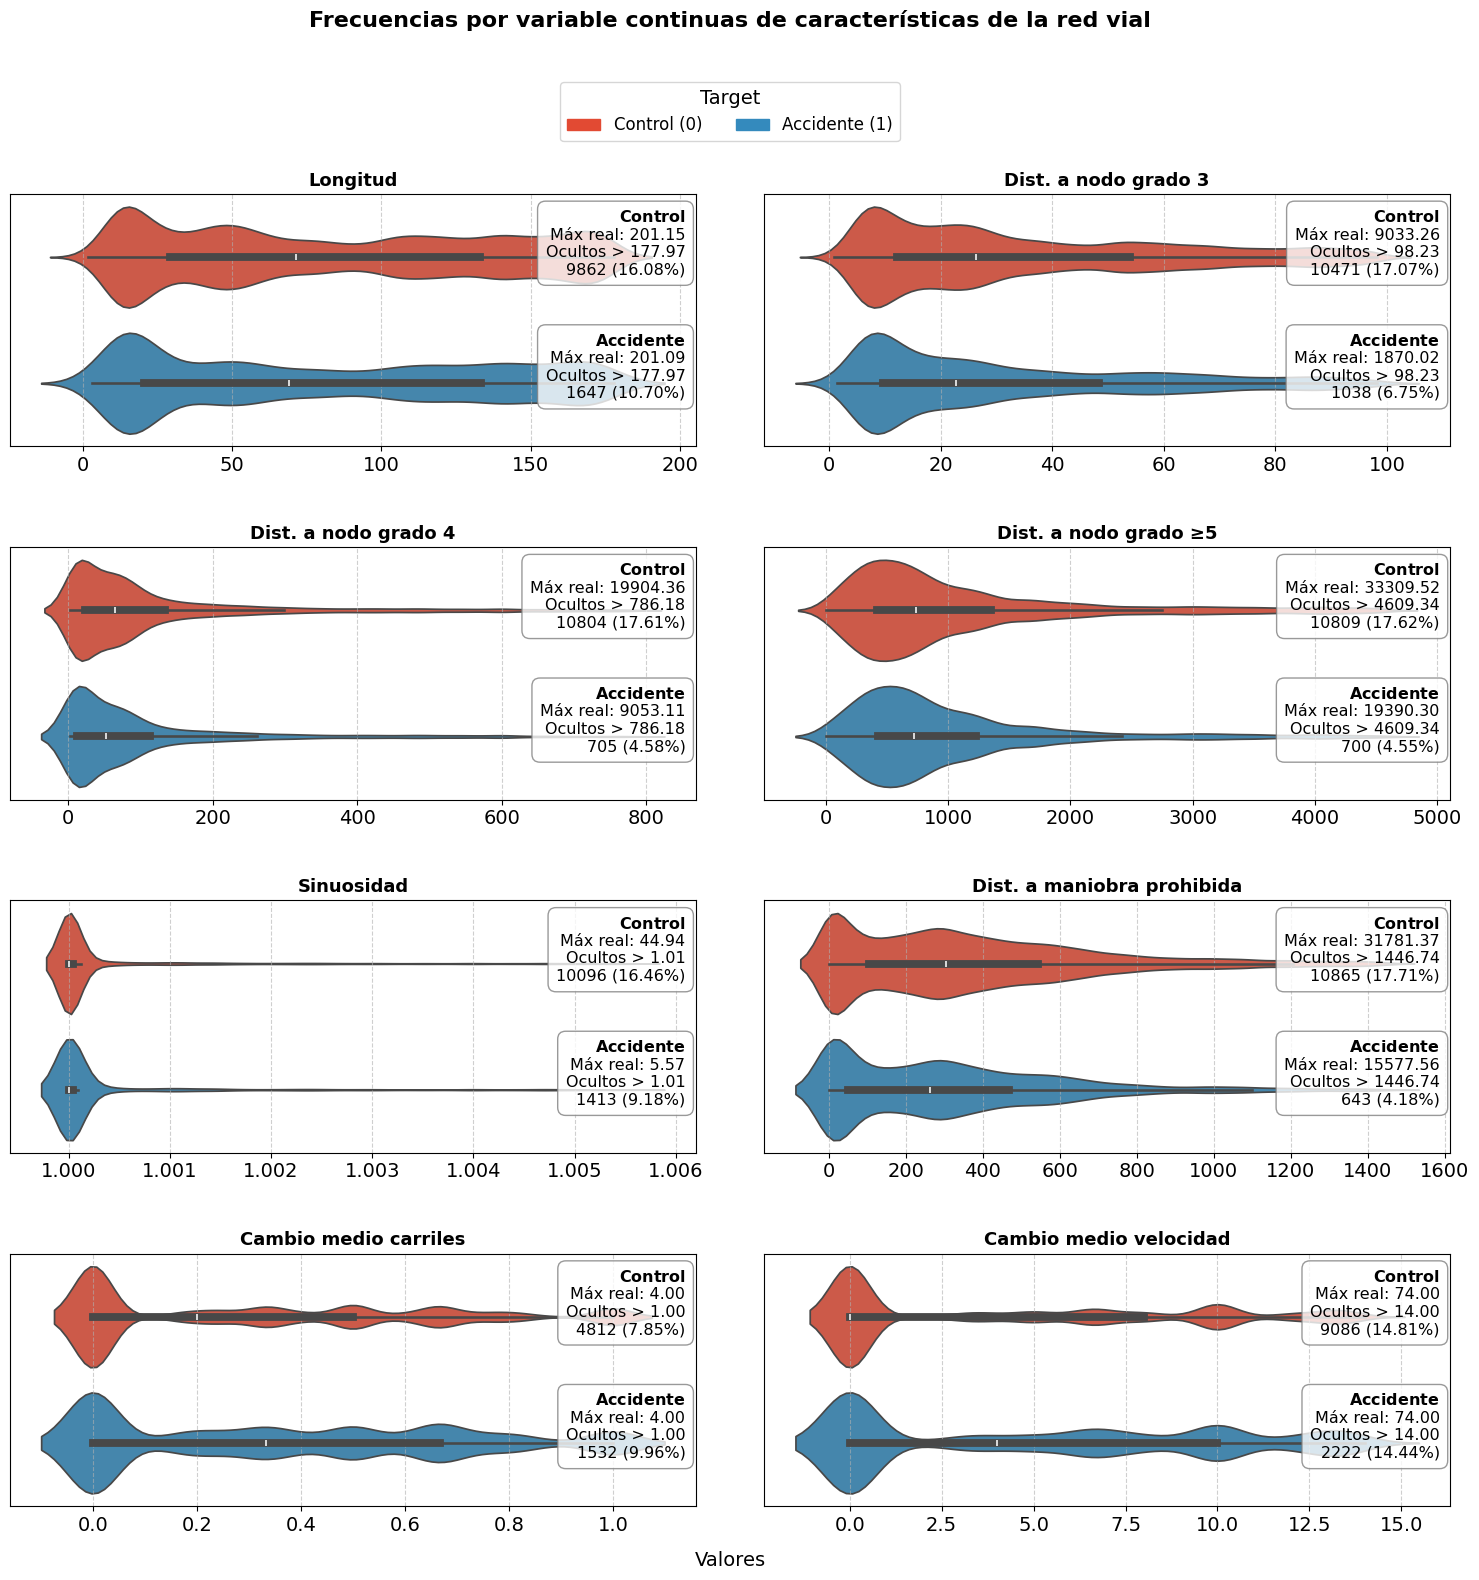

In [11]:
# Variables
var_vial_continuas = [
    'LONGITUD', 'DIST_NODO_3', 'DIST_NODO_4', 'DIST_NODO_5_MAS', 
    'SINUOSIDAD', 'DIST_MAN_PROH', 'DELTA_CARRILES_MEAN', 'DELTA_VELOCIDAD_MEAN'
]

df_train['TARGET_CAT'] = pd.Categorical(
    df_train['TARGET'].map({0: 'Control (0)', 1: 'Accidente (1)'}),
    categories=['Control (0)', 'Accidente (1)'], ordered=True
    )

total_t0, total_t1 = len(df_control), len(df_acc_a)
colores = ['#E24A33', '#348ABD']

# ESTADÍSTICAS DESCRIPTIVAS
# Seleccionamos solo las métricas clave que nos interesan
metricas_clave = ['min', 'mean', 'std', '25%', '50%', '75%', 'max']

for var in var_vial_continuas:
    titulo = nombres_vars.get(var, var)
    print(f"\nESTADÍSTICAS: {titulo}")
    
    # Calculo de estadísticos
    df_desc_var = df_train.groupby('TARGET_CAT', observed=True)[var].describe()
    df_desc_var.index.name = 'Target'
    df_desc_var = df_desc_var[metricas_clave].round(3)
    display(df_desc_var)

# GRÁFICO
fig_vio, axes_vio = plt.subplots(4, 2, figsize=(16, 16)) 
axes_vio = axes_vio.flatten()

for i, var in enumerate(var_vial_continuas):
    ax = axes_vio[i]
    titulo = nombres_vars.get(var, var)
    
    # Manejo de outliers: Percentil 85 general (para mantener la misma escala)
    limite_visual = df_train[var].quantile(0.85)

    # Máximo real separado por clase
    max_t0 = df_control[var].max()
    max_t1 = df_acc[var].max()

    # Cuántos casos se van a ocultar
    df_outliers = df_train[df_train[var] > limite_visual]
    num_outliers = len(df_outliers)
    
    # Filtrado sin ouliers
    datos_plot = df_train[df_train[var] <= limite_visual]
    
    # Gráfico de violín horizontal
    sns.violinplot(
        data=datos_plot, x=var, y='TARGET_CAT', hue='TARGET_CAT', 
        ax=ax, palette=colores, legend=False
    )
    
    ax.set_title(f'{titulo}', fontsize=13, fontweight='bold')
    ax.set_xlabel('',) 
    ax.set_ylabel('') 
    ax.grid(axis='x', linestyle='--', alpha=0.5)
    
    # Agregar texto
    if num_outliers > 0:
        # Conteo por clase
        outliers_t0 = (df_outliers['TARGET'] == 0).sum()
        outliers_t1 = (df_outliers['TARGET'] == 1).sum()
        
        # Porcentaje respecto al total de cada clase
        pct_t0 = (outliers_t0 / total_t0) * 100
        pct_t1 = (outliers_t1 / total_t1) * 100
        
        # Texto estructurado para controles
        texto_outlier_0 = (
            r"$\bf{Control}$" + "\n"
            f"Máx real: {max_t0:.2f}\n"
            f"Ocultos > {limite_visual:.2f}\n"
            f"{outliers_t0} ({pct_t0:.2f}%)"
        )

        # Texto estructurado para accidentes
        texto_outlier_1 = (
            r"$\bf{Accidente}$" + "\n"
            f"Máx real: {max_t1:.2f}\n"
            f"Ocultos > {limite_visual:.2f}\n"
            f"{outliers_t1} ({pct_t1:.2f}%)"
        )
        
        # Posiciones
        ax.text(0.985, 0.94, texto_outlier_0, transform=ax.transAxes, 
                ha='right', va='top', fontsize=11.5, 
                bbox=dict(facecolor='white', alpha=0.8, edgecolor='gray', boxstyle='round,pad=0.5'))
        ax.text(0.985, 0.45, texto_outlier_1, transform=ax.transAxes, 
                ha='right', va='top', fontsize=11.5, 
                bbox=dict(facecolor='white', alpha=0.8, edgecolor='gray', boxstyle='round,pad=0.5'))
        ax.set_yticks([])
        ax.tick_params(axis='x', rotation=0, labelsize=14)
        ax.grid(axis='x', linestyle='--', alpha=0.6)

# Agregar leyenda global para la figura
handles = [plt.Rectangle((0,0),1,1, color=colores[0]), plt.Rectangle((0,0),1,1, color=colores[1])]
fig_vio.legend(handles, ['Control (0)', 'Accidente (1)'], loc='upper center', 
            bbox_to_anchor=(0.5, 0.945), ncol=2, frameon=True, title='Target', 
            fontsize=12, title_fontsize=14)

fig_vio.tight_layout()
fig_vio.suptitle("Frecuencias por variable continuas de características de la red vial", fontsize=16, fontweight='bold', y=0.985)
fig_vio.supxlabel('Valores', fontsize=14)
fig_vio.subplots_adjust(top=0.87, bottom=0.05, left=0.05, right=0.95, hspace=0.4, wspace=0.1)
plt.show(fig_vio)

## 5. Caracterización climática

El análisis meteorológico utiliza dos enfoques según la naturaleza de la variable y compara las observaciones de accidentes con las de control.

### 5.1 Precipitación: discretización en rangos

Dado el exceso de ceros en la lluvia, `PRECIP_SUM_PREV` y `PRECIP_MAX_PREV` se discretizan en intervalos de 3 mm para comparar las frecuencias de respuesta entre casos y controles.


TABLA DE FRECUENCIAS: Precip. acumulada previa


Precip. acumulada previa,0,0-3.0,3.0-6.0,6.0-9.0,9.0-12.0,12.0-15.0,15.0-18.0,18.0-21.0,21.0-24.0,24.0-27.0,27.0-30.0,30.0-33.0,Total
Target,,,,,,,,,,,,,
Control (0),50611 (82.5%),8878 (14.5%),988 (1.6%),526 (0.9%),141 (0.2%),96 (0.2%),52 (0.1%),27 (0.0%),9 (0.0%),2 (0.0%),3 (0.0%),2 (0.0%),61335 (100.0%)
Accidente (1),12753 (82.9%),2167 (14.1%),248 (1.6%),130 (0.8%),40 (0.3%),26 (0.2%),15 (0.1%),6 (0.0%),0 (0.0%),0 (0.0%),2 (0.0%),0 (0.0%),15387 (100.0%)
Total,63364 (82.6%),11045 (14.4%),1236 (1.6%),656 (0.9%),181 (0.2%),122 (0.2%),67 (0.1%),33 (0.0%),9 (0.0%),2 (0.0%),5 (0.0%),2 (0.0%),76722 (100.0%)



TABLA DE FRECUENCIAS: Precip. máx. previa


Precip. máx. previa,0,0-3.0,3.0-6.0,6.0-9.0,9.0-12.0,12.0-15.0,15.0-18.0,21.0-24.0,Total
Target,,,,,,,,,
Control (0),50611 (82.5%),9841 (16.0%),706 (1.2%),120 (0.2%),47 (0.1%),4 (0.0%),0 (0.0%),6 (0.0%),61335 (100.0%)
Accidente (1),12753 (82.9%),2412 (15.7%),176 (1.1%),36 (0.2%),7 (0.0%),2 (0.0%),1 (0.0%),0 (0.0%),15387 (100.0%)
Total,63364 (82.6%),12253 (16.0%),882 (1.1%),156 (0.2%),54 (0.1%),6 (0.0%),1 (0.0%),6 (0.0%),76722 (100.0%)


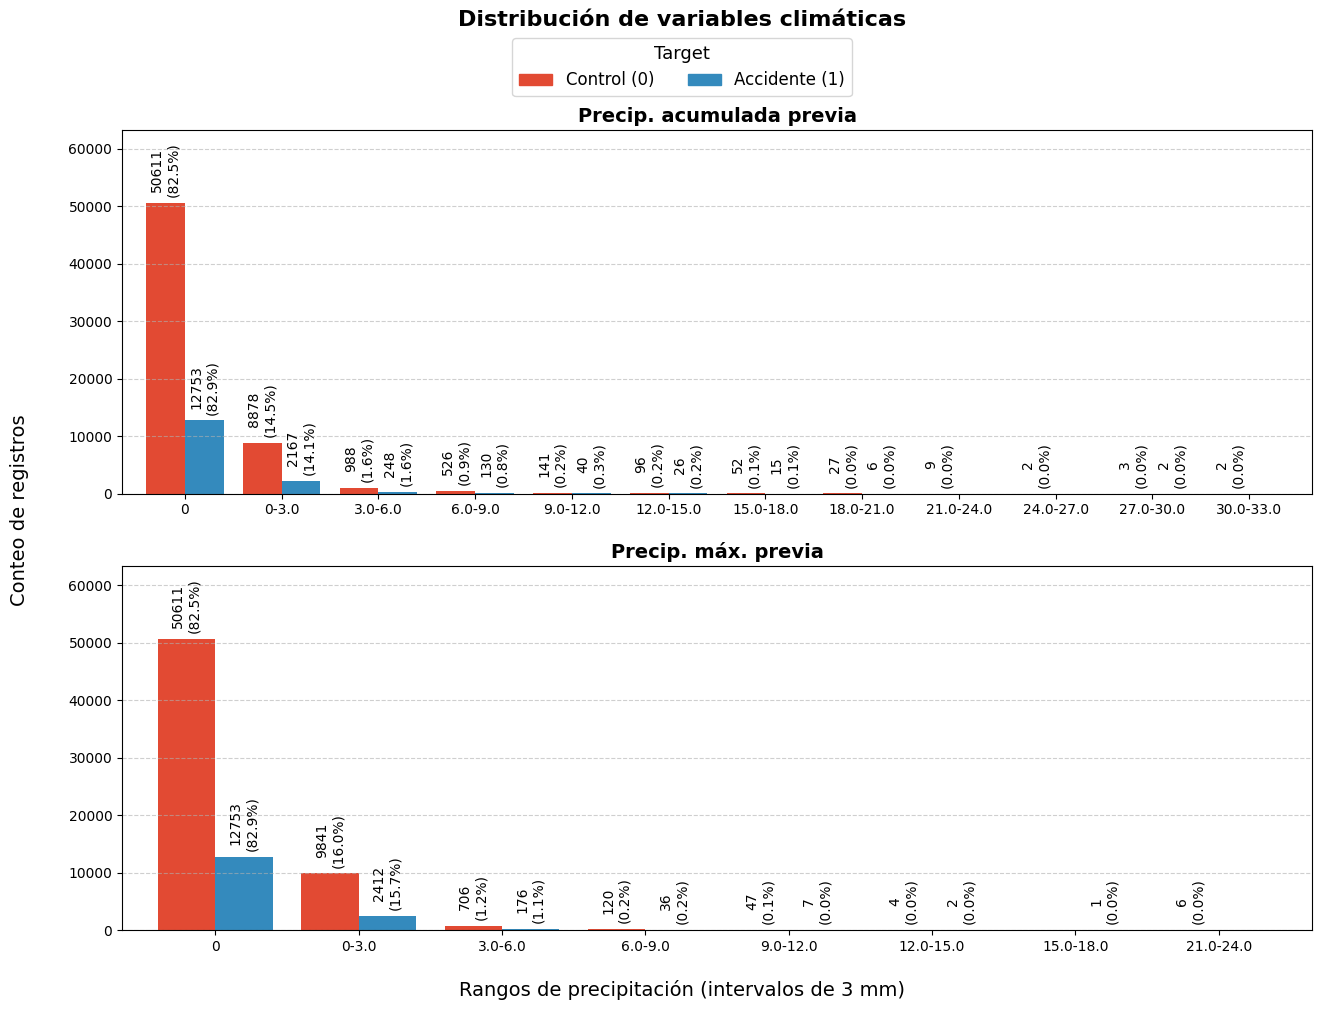

In [12]:
# Totales
total_t0, total_t1 = len(df_control), len(df_acc_a)

# Categorización
serie_target = pd.Categorical(
    df_train['TARGET'].map({0: 'Control (0)', 1: 'Accidente (1)'}),
    categories=['Control (0)', 'Accidente (1)'], ordered=True
)
df_train['TARGET_CAT'] = serie_target

colores = ['#E24A33', '#348ABD']
handles_leyenda = [plt.Rectangle((0,0),1,1, color=colores[0]), plt.Rectangle((0,0),1,1, color=colores[1])]

# Variables
var_clima_precip = ['PRECIP_SUM_PREV', 'PRECIP_MAX_PREV']

# GRÁFICA DE BARRAS
fig, axes = plt.subplots(2, 1, figsize=(14, 10))

for i, var in enumerate(var_clima_precip):
    ax = axes[i]
    titulo = nombres_vars.get(var, var)
    max_real = df_train[var].max()
    rango_col = f'{var}_RANGO'
    
    # Creación de Bins
    if max_real > 0:
        paso = 3
        limite = max_real + paso
        bins_positivos = [round(x, 2) for x in np.arange(paso, limite, paso)]
        bins = [-0.001, 0.0001] + bins_positivos
        
        labels = ['0', f'0-{bins_positivos[0]}']
        for j in range(len(bins_positivos)-1):
            labels.append(f'{bins_positivos[j]}-{bins_positivos[j+1]}')
            
        df_train[rango_col] = pd.cut(df_train[var], bins=bins, labels=labels, include_lowest=True)
    else:
        df_train[rango_col] = '0'
        labels = ['0']
    
    categorias_validas = [l for l in labels if l in df_train[rango_col].dropna().unique()]
    serie_rango = pd.Categorical(df_train[rango_col], categories=categorias_validas, ordered=True)
    
    # Tablas de frecuencia
    df_display = tabla_crosstab_combinada(serie_target, serie_rango, titulo)
    print(f"\nTABLA DE FRECUENCIAS: {titulo}")
    display(df_display)
    
    # Datos para el plot
    df_plot, df_texto = frecuencia_y_texto(df_display)
    
    # Graficación
    df_plot.plot(kind='bar', ax=ax, color=colores, width=0.8)
    
    ax.set_title(f'{titulo}', fontsize=14, fontweight='bold')
    ax.set_xlabel('')
    ax.set_ylabel('')
    ax.tick_params(axis='x', rotation=0) 
    ax.grid(axis='y', linestyle='--', alpha=0.6)
    
    max_val = df_plot.max().max()
    ax.set_ylim(0, max_val * 1.25)
    
    # Anotaciones
    conteos = df_plot.values.flatten('F')
    textos = df_texto.values.flatten('F')
    
    for p, conteo, texto in zip(ax.patches, conteos, textos):
        if conteo > 0:
            ax.text(p.get_x() + p.get_width() / 2., p.get_height() + (max_val * 0.02),
                    texto, ha='center', va='bottom', fontsize=10, color='black', rotation = 90)
            
    if ax.get_legend() is not None:
        ax.get_legend().remove()

# Leyenda y ajustes
fig.legend(handles_leyenda, ['Control (0)', 'Accidente (1)'], loc='upper center', 
            bbox_to_anchor=(0.5, 0.98), ncol=2, frameon=True, title='Target', 
            fontsize=12, title_fontsize=13)
fig.supylabel('Conteo de registros', fontsize=14)
fig.supxlabel('Rangos de precipitación (intervalos de 3 mm)', fontsize=14)
fig.suptitle("Distribución de variables climáticas", fontsize=16, fontweight='bold', y=1.0)
fig.subplots_adjust(top=0.88, bottom=0.08, left=0.1, right=0.95, hspace=0.2)
plt.show(fig)

### 5.2 Variables continuas

Las variables de temperatura (`TEMP_MEAN_PREV, TEMP_MIN_PREV`, `APP_TEMP_MEAN_PREV`, `SOIL_TEMP_MEAN_PREV`), humedad del suelo (`SOIL_MOISTURE_MEAN_PREV`), cobertura de nubes (`CLOUD_COVER_MEAN_PREV`) y viento (`WIND_GUSTS_MAX_PREV`, `WIND_SPEED_MEAN_PREV`) se examinan mediante estadísticos descriptivos y gráficos comparativos de violín, para identificar sesgos, desplazamientos en la mediana o cambios en la dispersión entre accidentes y controles.


ESTADÍSTICAS: Rachas viento previas


,min,mean,std,25%,50%,75%,max
Target,,,,,,,
Control (0),3.24,28.775,10.597,20.88,27.36,35.28,86.76
Accidente (1),3.24,28.372,10.456,20.52,27.00,34.92,78.48



ESTADÍSTICAS: Velocidad viento previa


,min,mean,std,25%,50%,75%,max
Target,,,,,,,
Control (0),1.081,9.929,4.873,6.356,8.899,12.524,41.643
Accidente (1),0.958,9.925,4.835,6.343,8.932,12.474,37.903



ESTADÍSTICAS: Temp. media previa


...

,min,mean,std,25%,50%,75%,max
Target,,,,,,,
Control (0),0.0,42.454,36.007,5.667,37.000,76.667,100.0
Accidente (1),0.0,42.599,36.101,5.833,36.833,77.167,100.0



ESTADÍSTICAS: Temp. suelo previa


,min,mean,std,25%,50%,75%,max
Target,,,,,,,
Control (0),0.464,22.274,6.830,17.408,21.517,26.967,48.481
Accidente (1),5.208,22.439,6.873,17.492,21.675,27.200,45.972



ESTADÍSTICAS: Humedad suelo previa


,min,mean,std,25%,50%,75%,max
Target,,,,,,,
Control (0),-0.000,0.146,0.081,0.087,0.114,0.178,0.436
Accidente (1),-0.001,0.143,0.080,0.087,0.107,0.173,0.436


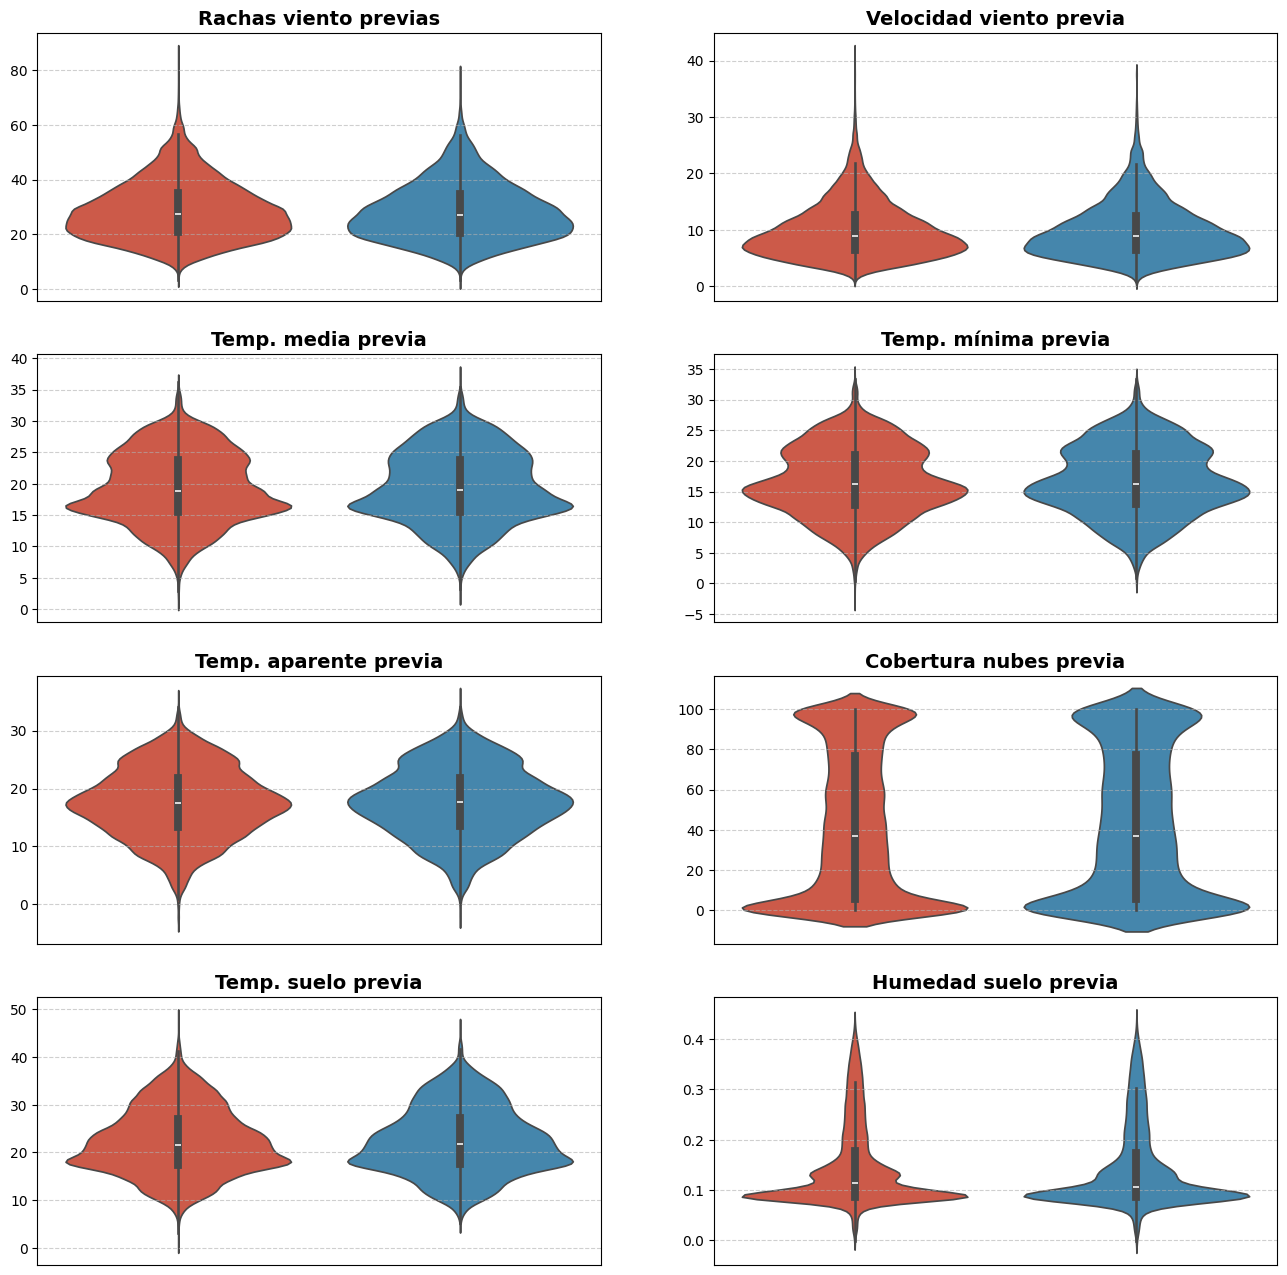

In [14]:
# Variables
var_clima_continuas = [
    'WIND_GUSTS_MAX_PREV', 'WIND_SPEED_MEAN_PREV', 'TEMP_MEAN_PREV', 
    'TEMP_MIN_PREV', 'APP_TEMP_MEAN_PREV', 'CLOUD_COVER_MEAN_PREV', 
    'SOIL_TEMP_MEAN_PREV', 'SOIL_MOISTURE_MEAN_PREV'
]

# Totales
total_t0, total_t1 = len(df_control), len(df_acc)

# Categprización
df_train['TARGET_CAT'] = pd.Categorical(
    df_train['TARGET'].map({0: 'Control (0)', 1: 'Accidente (1)'}),
    categories=['Control (0)', 'Accidente (1)'], ordered=True
)

colores = ['#E24A33', '#348ABD']

# ESTADÍSTICAS DESCRIPTIVAS
# Seleccionamos solo las métricas clave que nos interesan
metricas_clave = ['min', 'mean', 'std', '25%', '50%', '75%', 'max']

for var in var_clima_continuas:
    titulo = nombres_vars.get(var, var)
    print(f"\nESTADÍSTICAS: {titulo}")
    
    # Calculo de estadísticos
    df_desc_var = df_train.groupby('TARGET_CAT', observed=True)[var].describe()
    df_desc_var.index.name = 'Target'
    df_desc_var = df_desc_var[metricas_clave].round(3)
    display(df_desc_var)

# GRÁFICO
fig_vio, axes_vio = plt.subplots(4, 2, figsize=(16, 16)) 
axes_vio = axes_vio.flatten()

for i, var in enumerate(var_clima_continuas):
    ax = axes_vio[i]
    titulo = nombres_vars.get(var, var)

    # Graficación
    sns.violinplot(
        data=df_train, x='TARGET_CAT', y=var, hue='TARGET_CAT', 
        ax=ax, palette=colores, legend=False
    )
    
    ax.set_title(titulo, fontsize=14, fontweight='bold')
    ax.set_ylabel('') 
    ax.set_xlabel('') 
    ax.set_xticks([])
    ax.grid(axis='y', linestyle='--', alpha=0.6)

# Leyenda y ajustes
handles_leyenda = [plt.Rectangle((0,0),1,1, color=colores[0]), plt.Rectangle((0,0),1,1, color=colores[1])]
fig.legend(handles_leyenda, ['Control (0)', 'Accidente (1)'], loc='upper center', 
            bbox_to_anchor=(0.5, 0.98), ncol=2, frameon=True, title='Target', 
            fontsize=12, title_fontsize=14)

fig.suptitle("Distribución de variables climáticas", fontsize=18, fontweight='bold', y=1.03)
fig.supylabel('Conteo de registros', fontsize=14)
fig.subplots_adjust(top=0.87, bottom=0.05, left=0.05, right=0.95, hspace=0.15, wspace=0.1)
plt.show(fig)

## 6. Variables de memoria histórica local

Se evaluaron las tres variables de memoria (`ACC_LOCAL_2W`, `ACC_LOCAL_1M` y `ACC_LOCAL_2M`) mediante gráficos de barras pareadas, para poder cuantificar la frecuencia con la que los segmentos de la red registraron eventos previos.


TABLA DE FRECUENCIAS: Accidentes 2 semanas


Accidentes 2 semanas,0,1,2,3,4,5,Total
Target,,,,,,,
Control (0),58475 (95.3%),2450 (4.0%),351 (0.6%),50 (0.1%),8 (0.0%),1 (0.0%),61335 (100.0%)
Accidente (1),13916 (90.4%),1274 (8.3%),172 (1.1%),19 (0.1%),5 (0.0%),1 (0.0%),15387 (100.0%)
Total,72391 (94.4%),3724 (4.9%),523 (0.7%),69 (0.1%),13 (0.0%),2 (0.0%),76722 (100.0%)



TABLA DE FRECUENCIAS: Accidentes 1 mes


Accidentes 1 mes,0,1,2,3,4,5,Total
Target,,,,,,,
Control (0),58557 (95.5%),2404 (3.9%),325 (0.5%),42 (0.1%),5 (0.0%),2 (0.0%),61335 (100.0%)
Accidente (1),13970 (90.8%),1217 (7.9%),172 (1.1%),24 (0.2%),4 (0.0%),0 (0.0%),15387 (100.0%)
Total,72527 (94.5%),3621 (4.7%),497 (0.6%),66 (0.1%),9 (0.0%),2 (0.0%),76722 (100.0%)



TABLA DE FRECUENCIAS: Accidentes 2 meses


Accidentes 2 meses,0,1,2,3,4,5,6,Total
Target,,,,,,,,
Control (0),56550 (92.2%),3650 (6.0%),859 (1.4%),200 (0.3%),45 (0.1%),26 (0.0%),5 (0.0%),61335 (100.0%)
Accidente (1),13006 (84.5%),1816 (11.8%),414 (2.7%),110 (0.7%),24 (0.2%),14 (0.1%),3 (0.0%),15387 (100.0%)
Total,69556 (90.7%),5466 (7.1%),1273 (1.7%),310 (0.4%),69 (0.1%),40 (0.1%),8 (0.0%),76722 (100.0%)


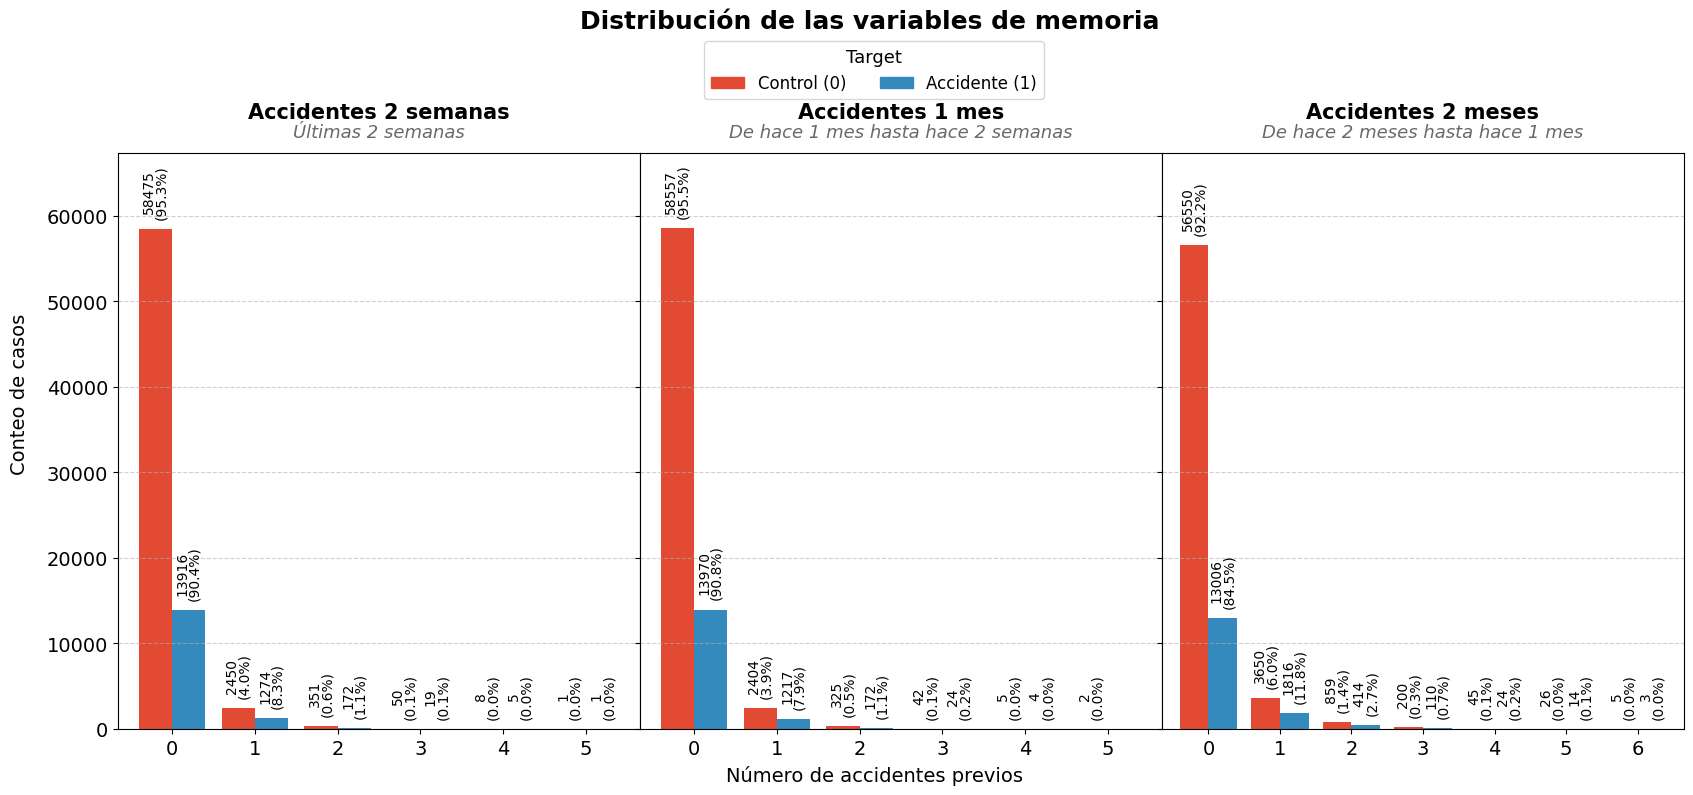

In [13]:
# Variables
var_memoria = ['ACC_LOCAL_2W', 'ACC_LOCAL_1M', 'ACC_LOCAL_2M']

# Límites
limites_tiempo = {
    'ACC_LOCAL_2W': 'Últimas 2 semanas',
    'ACC_LOCAL_1M': 'De hace 1 mes hasta hace 2 semanas',
    'ACC_LOCAL_2M': 'De hace 2 meses hasta hace 1 mes'
}

# Categorización
df_train['TARGET_CAT'] = pd.Categorical(
    df_train['TARGET'].map({0: 'Control (0)', 1: 'Accidente (1)'}),
    categories=['Control (0)', 'Accidente (1)'], ordered=True
)

# Extraemos los datos antes para conocer la altura máxima compartida
datos_graficos = []
max_global = 0

for var in var_memoria:
    titulo = nombres_vars.get(var, var)
    df_display = tabla_crosstab_combinada(df_train['TARGET_CAT'], df_train[var], titulo)
    print(f"\nTABLA DE FRECUENCIAS: {titulo}")
    display(df_display)
    df_plot, df_texto = frecuencia_y_texto(df_display)
    
    # Evaluar si este gráfico tiene el valor más alto hasta ahora
    max_local = df_plot.max().max()
    if max_local > max_global:
        max_global = max_local
        
    # Guardamos los datos para no recalcularlos en el bucle de graficación
    datos_graficos.append((var, titulo, df_display, df_plot, df_texto))

colores = ['#E24A33', '#348ABD']

# GRÁFICOS (1 Fila, 3 Columnas)
fig, axes = plt.subplots(1, 3, figsize=(18, 8), sharey=True)

for i, (var, titulo, df_display, df_plot, df_texto) in enumerate(datos_graficos):
    ax = axes[i]

    df_plot.plot(kind='bar', ax=ax, color=colores, width=0.8)

    # Textos
    ax.set_title(f'{titulo}', fontsize=15, fontweight='bold', pad=25)
    subtitulo = limites_tiempo.get(var, '')
    ax.text(0.5, 1.02, subtitulo, transform=ax.transAxes,
            ha='center', va='bottom', fontsize=13, color='dimgray', style='italic')

    ax.set_xlabel('')
    ax.set_ylabel('')
    ax.tick_params(axis='x', rotation=0, labelsize=14)
    ax.tick_params(axis='y', rotation=0, labelsize=14)
    ax.grid(axis='y', linestyle='--', alpha=0.6)

    if i > 0:
        ax.tick_params(labelleft=False)

    # Límite compartido
    ax.set_ylim(0, max_global * 1.15)

    # Anotaciones
    conteos = df_plot.values.flatten('F')
    textos = df_texto.values.flatten('F')

    for p, conteo, texto in zip(ax.patches, conteos, textos):
        if conteo > 0:
            ax.text(
                p.get_x() + p.get_width() / 2.,
                p.get_height() + (max_global * 0.02),
                texto,
                ha='center', va='bottom', fontsize=10, color='black',
                rotation=90, linespacing=0.85
            )

    if ax.get_legend() is not None:
        ax.get_legend().remove()

# Leyendas
handles = [plt.Rectangle((0,0),1,1, color=colores[0]), plt.Rectangle((0,0),1,1, color=colores[1])]
fig.legend(
    handles, ['Control (0)', 'Accidente (1)'], 
    loc='upper center', bbox_to_anchor=(0.5, 0.95), ncol=2, 
    frameon=True, title='Target', fontsize=12, title_fontsize=13
)

fig.tight_layout()
fig.suptitle("Distribución de las variables de memoria ", fontsize=18, fontweight='bold')
fig.supxlabel('Número de accidentes previos', fontsize=14)
fig.supylabel('Conteo de casos', fontsize=14)
fig.subplots_adjust(top=0.8, bottom=0.08, left=0.08, right=0.95, wspace=0)
plt.show(fig)